[*] Device: cuda:0
[*] Loading Models...
[*] Computing Embeddings...
[*] Running Alignment...
[*] Generating Modern 3D Plot...
[+] Saved modern_alignment_3d.pdf and .png


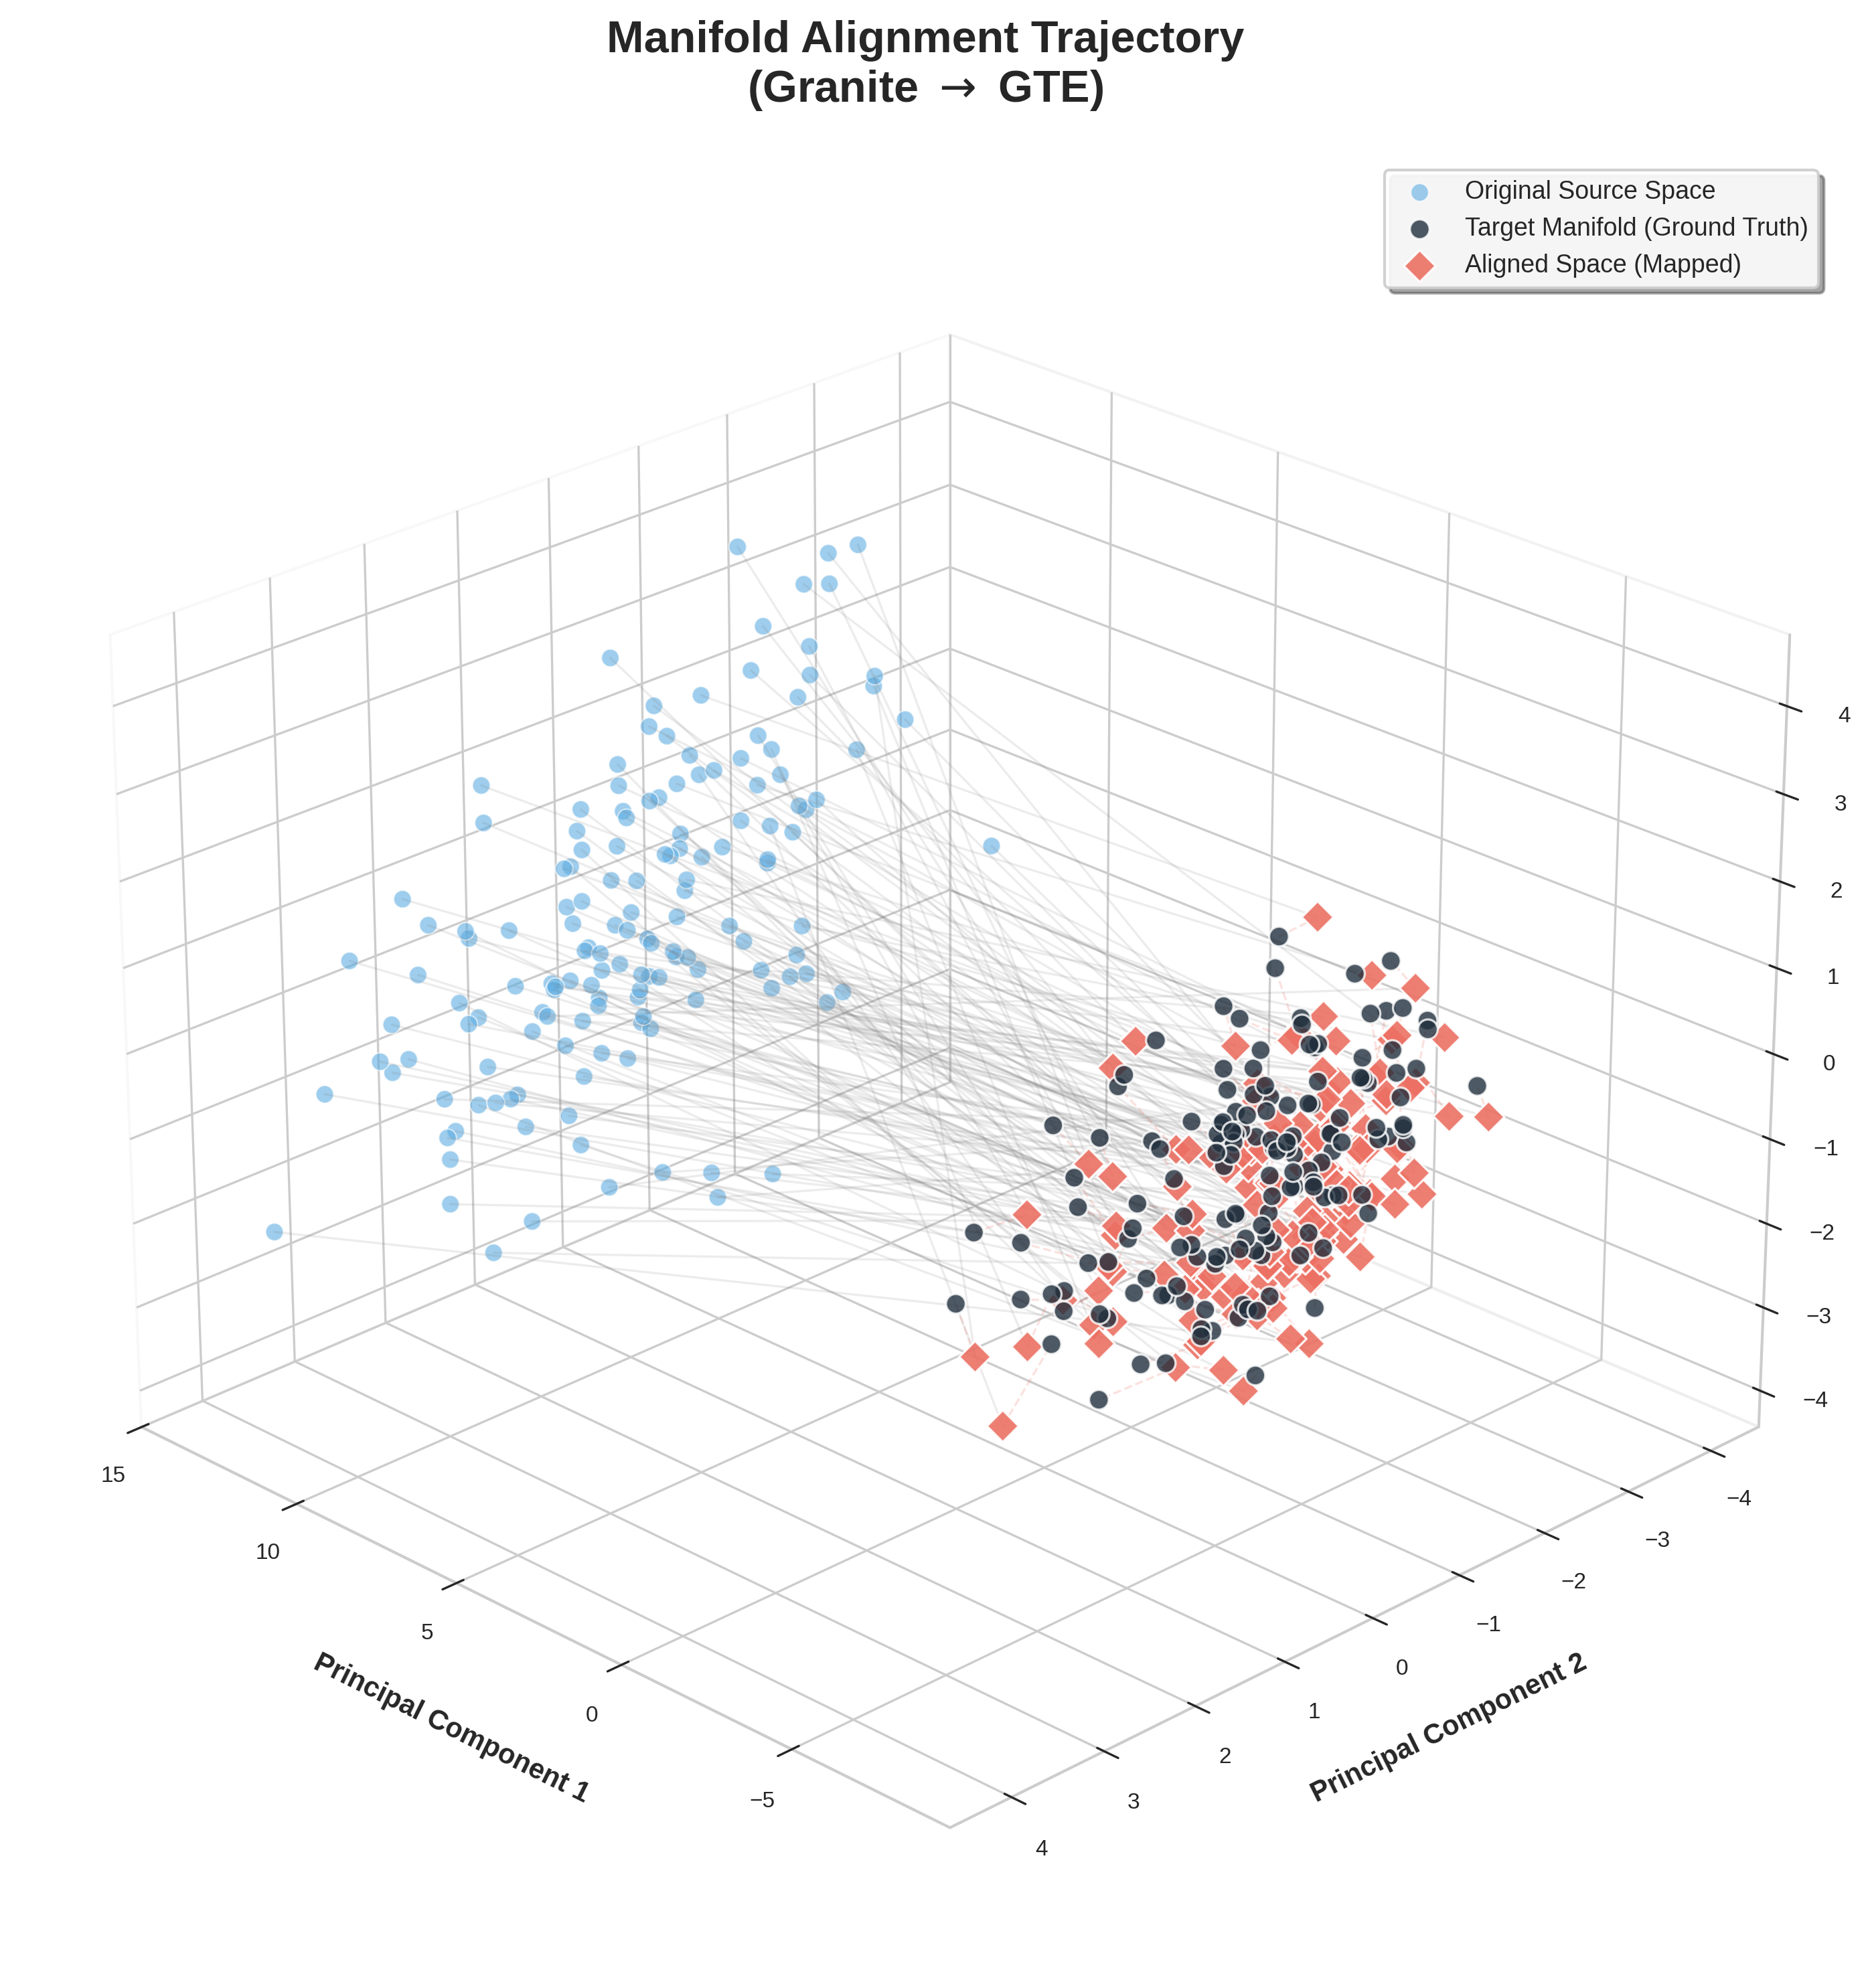

In [3]:
#!/usr/bin/env python3
"""
Modern 3D Visualization of Multimodal Alignment.
Generates publication-quality plots (PDF/PNG).
"""

import os
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from datasets import load_dataset
import seaborn as sns

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual"
TGT_NAME = "thenlper/gte-base"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 150       # Enough to see density, low enough to avoid clutter
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Modern Styling Setup
# -------------------------
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 8
plt.rcParams['ytick.labelsize'] = 8
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.dpi'] = 300

# Professional Palette
COLOR_SRC = '#5DADE2'   # Soft Blue (Start)
COLOR_MAP = '#EC7063'   # Vibrant Coral (Prediction)
COLOR_TGT = '#212F3D'   # Midnight Blue (Anchor)

# -------------------------
# Models
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    encoded = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    out = model(**encoded)
    mask = encoded["attention_mask"].unsqueeze(-1)
    hidden = out.last_hidden_state * mask
    embeddings = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
    return embeddings

# -------------------------
# Main Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")
    
    # 1. Load Data
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])
    
    # 2. Load Models
    print("[*] Loading Models...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    # 3. Compute Embeddings
    print("[*] Computing Embeddings...")
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)
    
    # 4. Load Mapper
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    mapper.eval()
    
    print("[*] Running Alignment...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb, memory=t_emb)
    
    # 5. PCA Reduction
    X_src = s_emb.detach().cpu().numpy()
    X_tgt = t_emb.detach().cpu().numpy()
    X_map = mapped_emb.detach().cpu().numpy()
    
    all_data = np.concatenate([X_src, X_tgt, X_map], axis=0)
    pca = PCA(n_components=3)
    all_pca = pca.fit_transform(all_data)
    
    pca_src = all_pca[:NUM_SAMPLES]
    pca_tgt = all_pca[NUM_SAMPLES:2*NUM_SAMPLES]
    pca_map = all_pca[2*NUM_SAMPLES:]
    
    # -------------------------
    # PLOTTING
    # -------------------------
    print("[*] Generating Modern 3D Plot...")
    
    # Use a clean style context
    with plt.style.context('seaborn-v0_8-whitegrid'):
        fig = plt.figure(figsize=(12, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        # Transparent background panels for cleaner look
        ax.xaxis.pane.fill = False
        ax.yaxis.pane.fill = False
        ax.zaxis.pane.fill = False
        ax.grid(True, linestyle=':', alpha=0.4)

        # 1. Plot Trajectories (The Alignment Flow)
        # We plot these first so points sit on top
        for i in range(NUM_SAMPLES):
            # Source -> Mapped (Transformation)
            ax.plot([pca_src[i,0], pca_map[i,0]], 
                    [pca_src[i,1], pca_map[i,1]], 
                    [pca_src[i,2], pca_map[i,2]], 
                    c='gray', alpha=0.15, linewidth=0.8, linestyle='-')
            
            # Mapped -> Target (Residual Error)
            ax.plot([pca_map[i,0], pca_tgt[i,0]], 
                    [pca_map[i,1], pca_tgt[i,1]], 
                    [pca_map[i,2], pca_tgt[i,2]], 
                    c=COLOR_MAP, alpha=0.2, linewidth=0.8, linestyle='--')

        # 2. Plot Points (Scatter)
        # Source: Smaller, lighter
        ax.scatter(pca_src[:,0], pca_src[:,1], pca_src[:,2], 
                   c=COLOR_SRC, s=40, alpha=0.6, edgecolors='white', linewidth=0.5, label='Original Source Space')
        
        # Target: Solid, Dark, Anchor
        ax.scatter(pca_tgt[:,0], pca_tgt[:,1], pca_tgt[:,2], 
                   c=COLOR_TGT, s=50, alpha=0.8, edgecolors='white', linewidth=0.8, label='Target Manifold (Ground Truth)')
        
        # Mapped: Distinctive marker, Vibrant
        ax.scatter(pca_map[:,0], pca_map[:,1], pca_map[:,2], 
                   c=COLOR_MAP, s=65, alpha=0.9, marker='D', edgecolors='white', linewidth=0.8, label='Aligned Space (Mapped)')

        # 3. Aesthetics
        ax.set_title(f'Manifold Alignment Trajectory\n(Granite $\\rightarrow$ GTE)', fontsize=16, fontweight='bold', pad=20)
        ax.set_xlabel('Principal Component 1', labelpad=10, fontweight='bold')
        ax.set_ylabel('Principal Component 2', labelpad=10, fontweight='bold')
        ax.set_zlabel('Principal Component 3', labelpad=10, fontweight='bold')
        
        # Remove axis ticks for cleaner "abstract" look (optional, remove lines if you want exact numbers)
        # ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])

        # Custom Legend
        legend = ax.legend(frameon=True, fancybox=True, shadow=True, loc='upper right')
        legend.get_frame().set_alpha(0.9)

        # Optimize view angle
        ax.view_init(elev=25, azim=135)

        plt.tight_layout()
        
        # Save high res
        plt.savefig("modern_alignment_3d.pdf", format='pdf', bbox_inches='tight')
        plt.savefig("modern_alignment_3d.png", format='png', dpi=300, bbox_inches='tight')
        print("[+] Saved modern_alignment_3d.pdf and .png")
        plt.show()

if __name__ == "__main__":
    main()

[*] Loading Data...
[*] Generating Embeddings...
[*] Mapping Source -> Target...
[*] Computing PCA for Topological Visualization...
[+] Saved visualization to structure_preservation_manifold.png


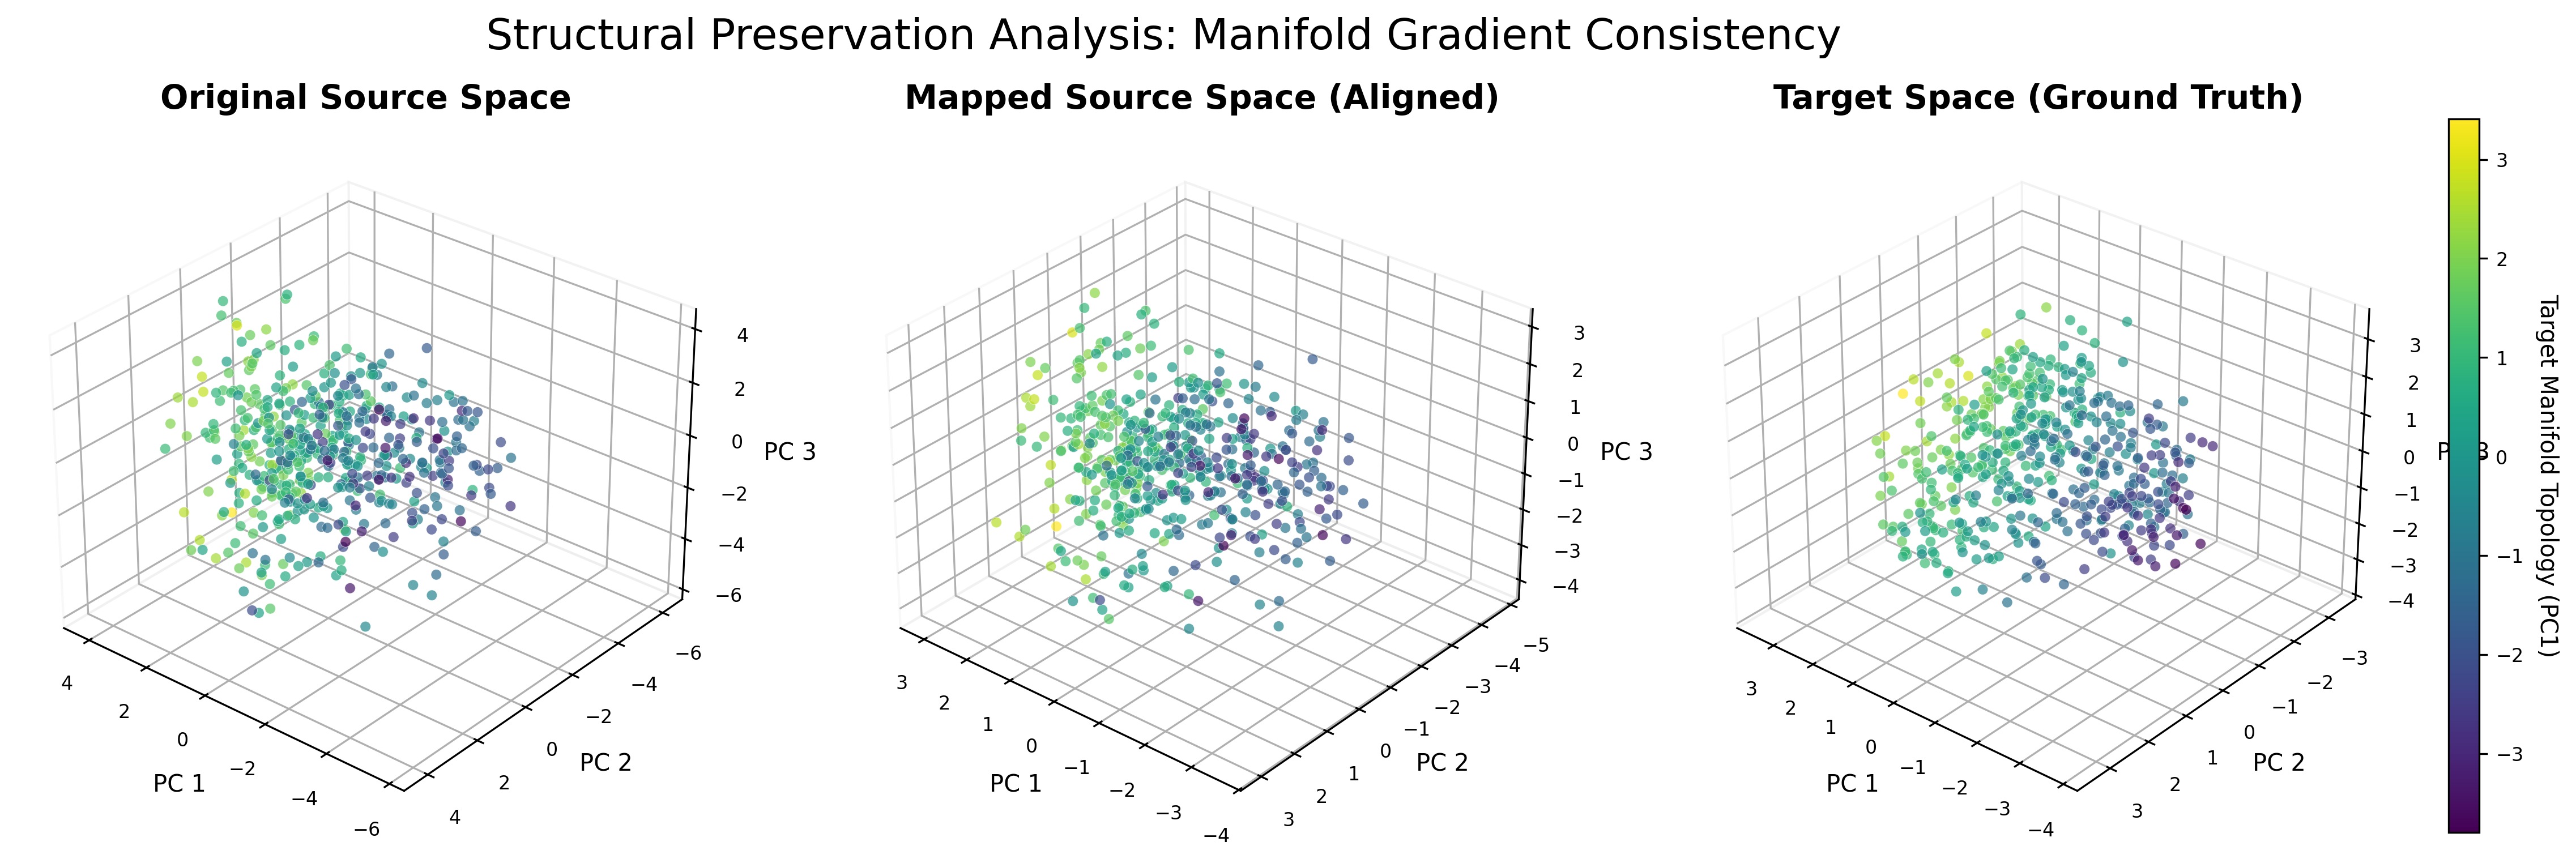

In [4]:
#!/usr/bin/env python3
"""
Structural Preservation Visualization (Manifold Coloring).
Demonstrates that Mapped Embeddings maintain the topological structure of the Target.
"""

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from datasets import load_dataset
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual"
TGT_NAME = "thenlper/gte-base"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

# We need enough samples to show a "surface" or "cloud"
NUM_SAMPLES = 500  
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Model Definitions
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    # Batching to avoid OOM
    batch_size = 64
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**encoded)
        mask = encoded["attention_mask"].unsqueeze(-1)
        hidden = out.last_hidden_state * mask
        emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Main Logic
# -------------------------
def main():
    # 1. Load Data
    print("[*] Loading Data...")
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])

    # 2. Load Models & Embed
    print("[*] Generating Embeddings...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)

    # 3. Load & Run Mapper
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    mapper.eval()
    
    print("[*] Mapping Source -> Target...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE))
    
    X_src = s_emb.numpy()
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.cpu().numpy()

    # ---------------------------------------------------------
    # MANIFOLD ALIGNMENT VISUALIZATION
    # ---------------------------------------------------------
    print("[*] Computing PCA for Topological Visualization...")

    # 1. Fit PCA on TARGET (The Ground Truth Structure)
    pca_tgt_fitter = PCA(n_components=3)
    tgt_pca = pca_tgt_fitter.fit_transform(X_tgt)

    # 2. Define Colors based on TARGET geometry
    # We color points based on their 1st Principal Component in Target space.
    # This creates a "Rainbow" across the Target manifold.
    # If Source/Mapped preserve structure, they should show the same rainbow gradient.
    color_indices = tgt_pca[:, 0] 
    norm = mcolors.Normalize(vmin=color_indices.min(), vmax=color_indices.max())
    cmap = cm.viridis # Professional gradient (Blue -> Green -> Yellow)

    # 3. Project Source and Mapped
    # Note: We fit separate PCAs to allow for rotation/projection differences
    # We want to see if the RELATIVE structure (the gradient) is preserved.
    src_pca = PCA(n_components=3).fit_transform(X_src)
    map_pca = PCA(n_components=3).fit_transform(X_map)

    # ---------------------------------------------------------
    # PLOT
    # ---------------------------------------------------------
    fig = plt.figure(figsize=(18, 6))
    
    titles = ["Original Source Space", "Mapped Source Space (Aligned)", "Target Space (Ground Truth)"]
    data_list = [src_pca, map_pca, tgt_pca]
    
    for i, (data, title) in enumerate(zip(data_list, titles)):
        ax = fig.add_subplot(1, 3, i+1, projection='3d')
        
        # Plot Scatter
        # KEY: We use the 'color_indices' derived from TARGET for ALL plots.
        # This tracks the identity of the points across transformations.
        p = ax.scatter(data[:,0], data[:,1], data[:,2], c=color_indices, cmap=cmap, s=20, alpha=0.7, edgecolors='w', linewidth=0.2)
        
        ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
        ax.set_xlabel('PC 1')
        ax.set_ylabel('PC 2')
        ax.set_zlabel('PC 3')
        
        # Clean look
        ax.grid(True, linestyle=':', alpha=0.3)
        ax.xaxis.pane.fill = False; ax.yaxis.pane.fill = False; ax.zaxis.pane.fill = False
        
        # Adjust view for best angle
        ax.view_init(elev=30, azim=130)

    # Add Colorbar to explain the topology
    cbar_ax = fig.add_axes([0.92, 0.15, 0.01, 0.7])
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_ax)
    cbar.set_label('Target Manifold Topology (PC1)', rotation=270, labelpad=15)

    plt.suptitle("Structural Preservation Analysis: Manifold Gradient Consistency", fontsize=18, y=0.95)
    
    out_file = "structure_preservation_manifold.png"
    plt.savefig(out_file, dpi=300, bbox_inches='tight')
    print(f"[+] Saved visualization to {out_file}")
    plt.show()

if __name__ == "__main__":
    main()

[*] Loading Data...
[*] Generating Embeddings...
[*] Mapping Source -> Target...
[*] Computing PCA Projections...
[+] Saved 2x2 visualization to full_projection_analysis.png


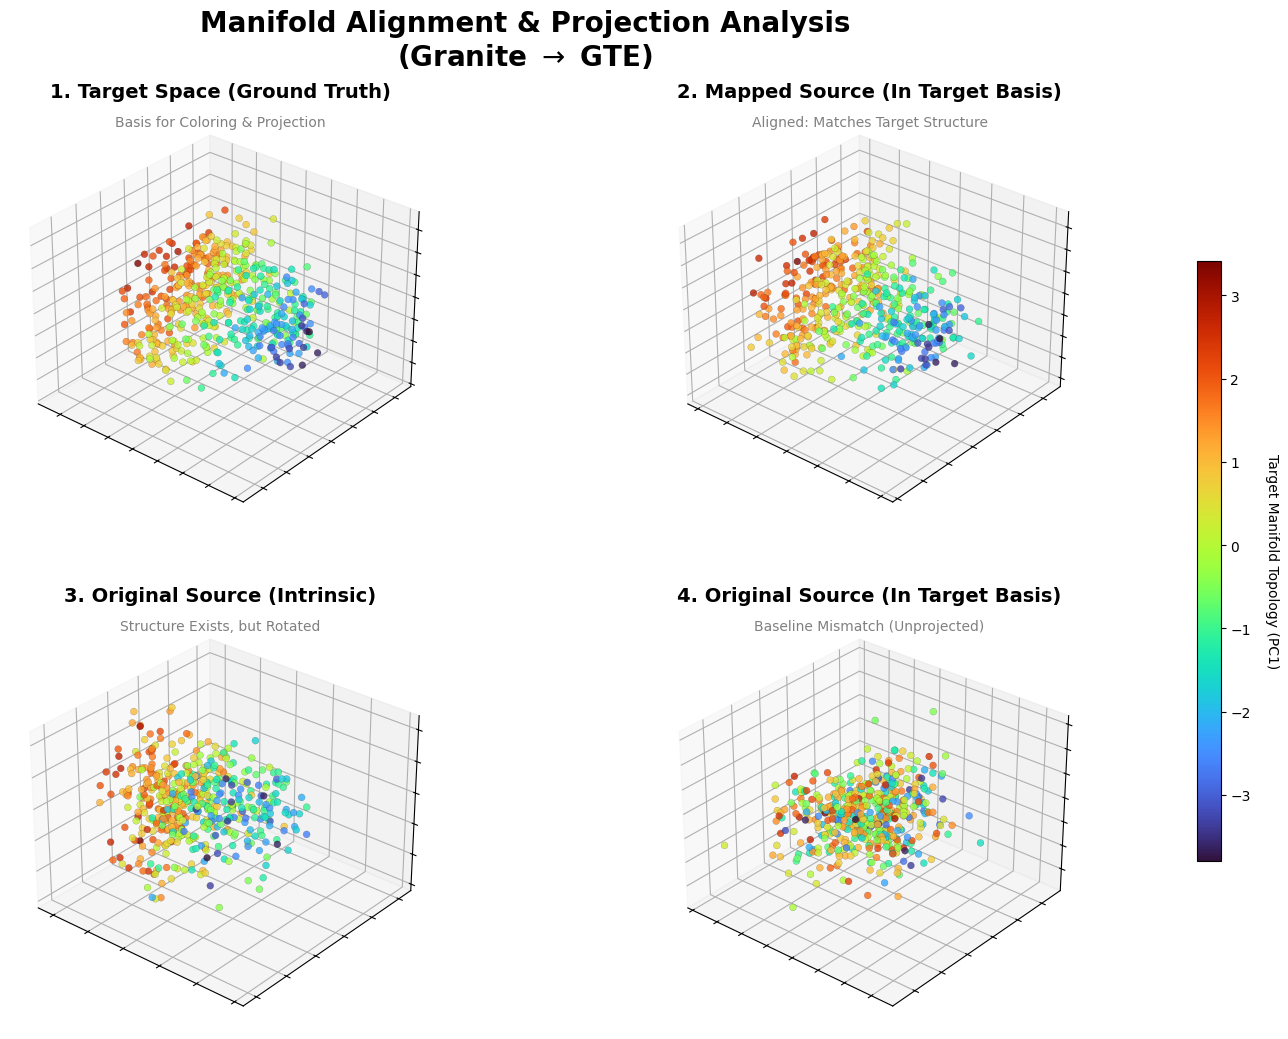

In [13]:
#!/usr/bin/env python3
"""
Structural Preservation & Projection Visualization.
Demonstrates:
1. Topology Consistency (Manifold Coloring).
2. Alignment Quality (Projecting Mapped data into Target Basis).
3. Baseline Mismatch (Projecting Original Source into Target Basis).
"""

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from datasets import load_dataset
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual"
TGT_NAME = "thenlper/gte-base"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 500  
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Model Definitions
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    batch_size = 64
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**encoded)
        mask = encoded["attention_mask"].unsqueeze(-1)
        hidden = out.last_hidden_state * mask
        emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Main Visualization Logic
# -------------------------
def main():
    # 1. Load Data
    print("[*] Loading Data...")
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])

    # 2. Embed
    print("[*] Generating Embeddings...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)

    # 3. Map
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    mapper.eval()
    
    print("[*] Mapping Source -> Target...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE))
    
    X_src = s_emb.numpy()
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.cpu().numpy()

    # ---------------------------------------------------------
    # PROJECTION ANALYSIS
    # ---------------------------------------------------------
    print("[*] Computing PCA Projections...")

    # A. Fit PCA on TARGET (The Ground Truth Basis)
    pca_tgt_fitter = PCA(n_components=3)
    tgt_pca = pca_tgt_fitter.fit_transform(X_tgt)

    # B. Define Topological Coloring (Gradient along Target PC1)
    color_indices = tgt_pca[:, 0] 
    norm = mcolors.Normalize(vmin=color_indices.min(), vmax=color_indices.max())
    cmap = cm.turbo # High contrast gradient

    # C. Project Everything into Target Basis (The "Test")
    # 1. Mapped -> Target Basis (Should look like Target)
    map_proj_tgt = pca_tgt_fitter.transform(X_map)
    
    # 2. Original Source -> Target Basis (Should look like noise/mismatch)
    # Note: Only valid if dimensions match. Granite(768) -> GTE(768) is valid.
    if X_src.shape[1] == X_tgt.shape[1]:
        src_proj_tgt = pca_tgt_fitter.transform(X_src)
    else:
        src_proj_tgt = np.zeros_like(tgt_pca) # Placeholder if dims differ

    # D. Intrinsic Source Structure (Control)
    # Fit PCA on Source itself to show it HAS structure, just unaligned
    src_pca_intrinsic = PCA(n_components=3).fit_transform(X_src)

    # ---------------------------------------------------------
    # 2x2 PLOT GRID
    # ---------------------------------------------------------
    fig = plt.figure(figsize=(16, 12))
    plt.subplots_adjust(wspace=0.1, hspace=0.2)
    
    # Common Plotting Helper
    def plot_subplot(idx, data, title, subtitle):
        ax = fig.add_subplot(2, 2, idx, projection='3d')
        p = ax.scatter(data[:,0], data[:,1], data[:,2], c=color_indices, cmap=cmap, s=25, alpha=0.8, edgecolors='k', linewidth=0.1)
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.text2D(0.5, 0.95, subtitle, transform=ax.transAxes, ha="center", fontsize=10, color='gray')
        ax.grid(True, linestyle=':', alpha=0.3)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        ax.view_init(elev=30, azim=130)
        return p

    # 1. Target Space (Reference)
    plot_subplot(1, tgt_pca, "1. Target Space (Ground Truth)", "Basis for Coloring & Projection")

    # 2. Mapped Source (Projected in Target)
    plot_subplot(2, map_proj_tgt, "2. Mapped Source (In Target Basis)", "Aligned: Matches Target Structure")

    # 3. Original Source (Intrinsic)
    plot_subplot(3, src_pca_intrinsic, "3. Original Source (Intrinsic)", "Structure Exists, but Rotated")

    # 4. Original Source (Projected in Target)
    plot_subplot(4, src_proj_tgt, "4. Original Source (In Target Basis)", "Baseline Mismatch (Unprojected)")

    # Colorbar
    cbar_ax = fig.add_axes([0.92, 0.25, 0.015, 0.5])
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_ax)
    cbar.set_label('Target Manifold Topology (PC1)', rotation=270, labelpad=20)

    plt.suptitle("Manifold Alignment & Projection Analysis\n(Granite $\\to$ GTE)", fontsize=20, fontweight='bold', y=0.96)
    
    out_file = "full_projection_analysis.png"
    plt.savefig(out_file, dpi=300, bbox_inches='tight')
    print(f"[+] Saved 2x2 visualization to {out_file}")
    plt.show()

if __name__ == "__main__":
    main()

[*] Device: cuda:0
[*] Loading Data...
[*] Generating Embeddings...
[*] Mapping Source -> Target...
[*] Computing UMAP Projections (This may take a moment)...


/home/pallucchini/NEW_ALIGNMENT_METHOD/env_new_alignment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



    ...projecting mapped data
    ...projecting source data
    ...computing intrinsic source UMAP


/home/pallucchini/NEW_ALIGNMENT_METHOD/env_new_alignment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



[*] Generating 5-Figure Dashboard...
[+] Saved umap_alignment_dashboard.png


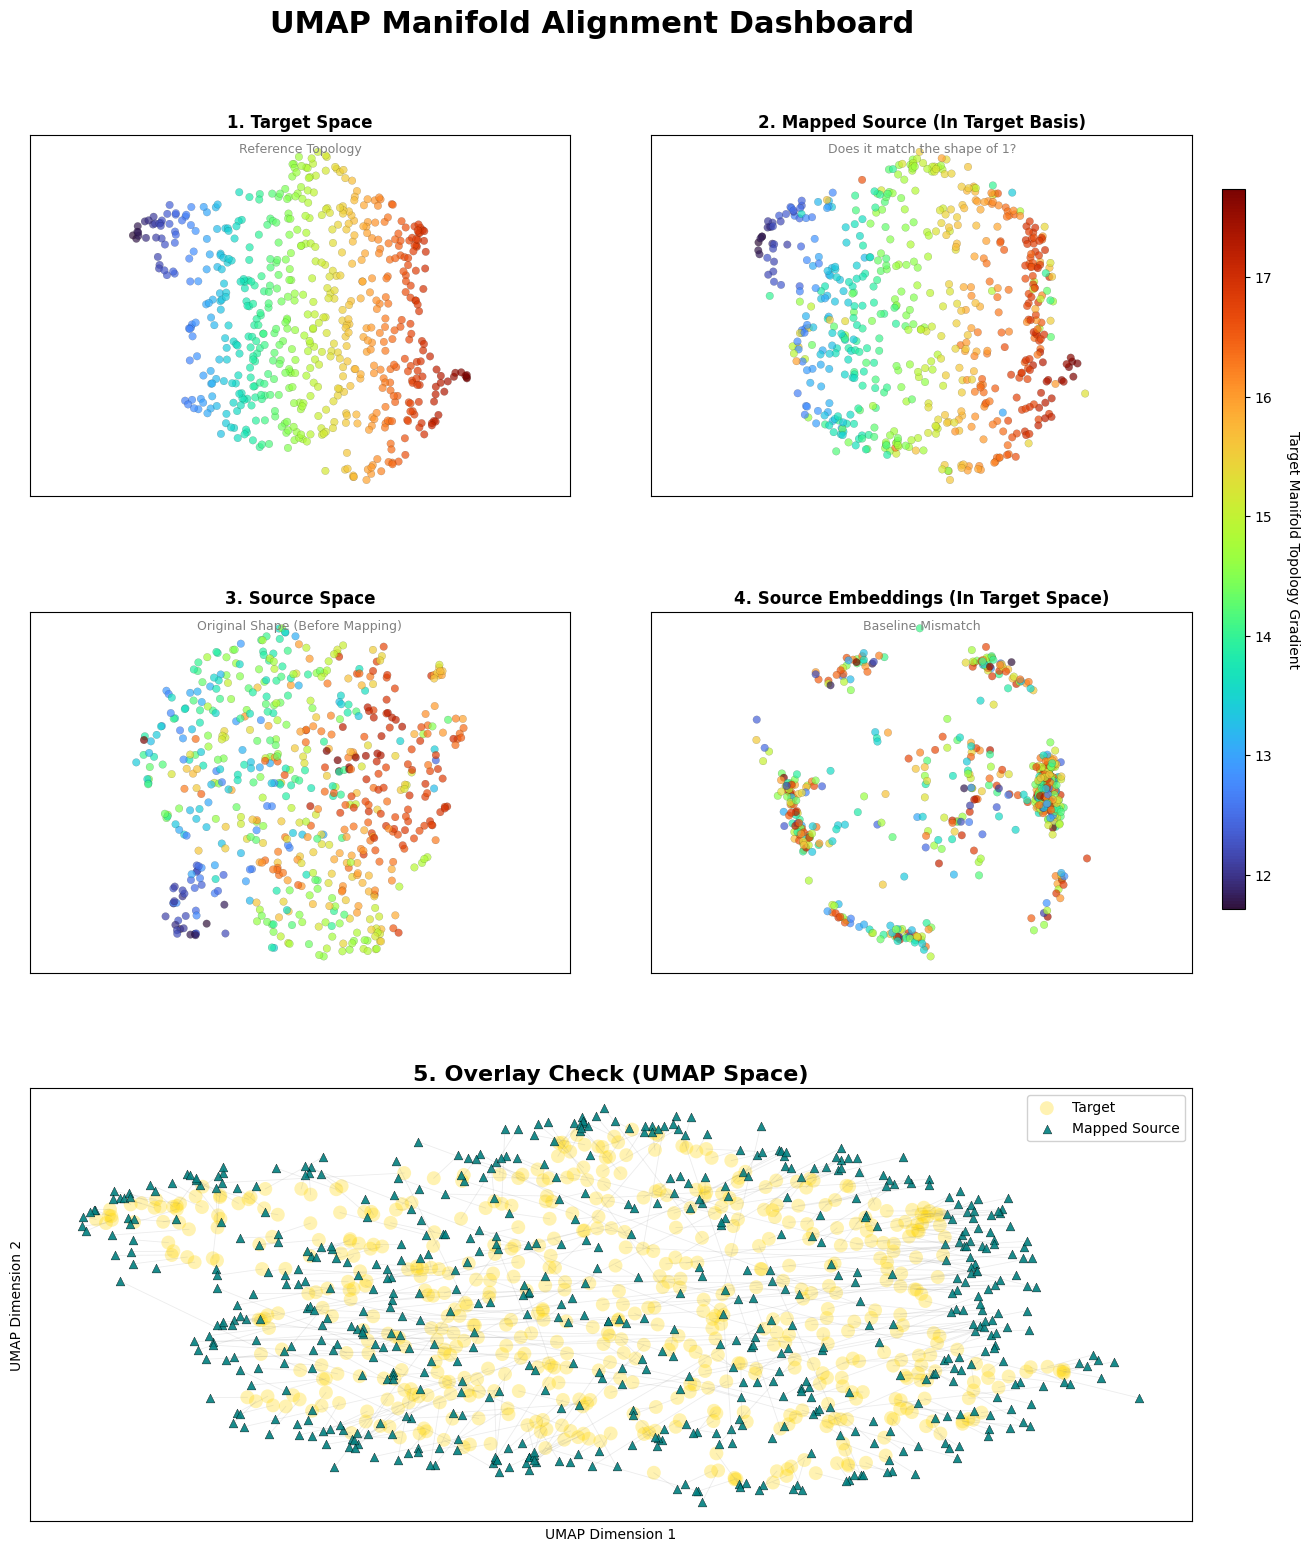

In [35]:
#!/usr/bin/env python3
"""
2D UMAP Manifold Alignment Dashboard.
Uses UMAP to unfold the topological structure of the embeddings.
"""

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import umap  # pip install umap-learn

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual"#"thenlper/gte-base"##
TGT_NAME = "intfloat/e5-base-v2"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 600  # UMAP likes a bit more data to find structure
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Model Definitions
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    batch_size = 64
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**encoded)
        mask = encoded["attention_mask"].unsqueeze(-1)
        hidden = out.last_hidden_state * mask
        emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Main Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")

    # 1. Load Data
    print("[*] Loading Data...")
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])

    # 2. Embed
    print("[*] Generating Embeddings...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)

    # 3. Map
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    try:
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    except Exception as e:
        print(f"[!] Error loading mapper: {e}. using random weights for demo.")
    mapper.eval()
    
    print("[*] Mapping Source -> Target...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE))
    
    X_src = s_emb.numpy()
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.cpu().numpy()

    # ---------------------------------------------------------
    # ANALYSIS SETUP (UMAP)
    # ---------------------------------------------------------
    print("[*] Computing UMAP Projections (This may take a moment)...")

    # A. Fit UMAP on TARGET (The Ground Truth Topology)
    # metric='cosine' is critical for embeddings!
    umap_fitter = umap.UMAP(n_components=2, metric='cosine', random_state=42, n_neighbors=15, min_dist=0.1)
    
    # We fit strictly on the Target. This defines the "map of the world".
    tgt_2d = umap_fitter.fit_transform(X_tgt)

    # B. Define Topological Coloring (Gradient along UMAP Axis 1)
    # This colors points based on where they live in the Target topology.
    color_indices = tgt_2d[:, 0] 
    norm = mcolors.Normalize(vmin=color_indices.min(), vmax=color_indices.max())
    cmap = cm.turbo 

    # C. Project Mapped & Source into Target Topology
    # "transform" forces the new data to fit into the existing Target map structure.
    print("    ...projecting mapped data")
    map_proj_tgt = umap_fitter.transform(X_map)
    
    print("    ...projecting source data")
    if X_src.shape[1] == X_tgt.shape[1]:
        src_proj_tgt = umap_fitter.transform(X_src)
    else:
        src_proj_tgt = np.zeros((len(X_src), 2))

    # D. Intrinsic Source Structure (Control)
    # Just to see what the source looks like by itself
    print("    ...computing intrinsic source UMAP")
    src_intrinsic_fitter = umap.UMAP(n_components=2, metric='cosine', random_state=42)
    src_2d_intrinsic = src_intrinsic_fitter.fit_transform(X_src)

    # ---------------------------------------------------------
    # FIGURE GENERATION
    # ---------------------------------------------------------
    print("[*] Generating 5-Figure Dashboard...")
    fig = plt.figure(figsize=(15, 18))
    gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1.2], hspace=0.3, wspace=0.15)

    def plot_subplot(loc, data, title, subtitle):
        ax = fig.add_subplot(loc)
        p = ax.scatter(data[:,0], data[:,1], c=color_indices, cmap=cmap, s=30, alpha=0.7, edgecolors='k', linewidth=0.1)
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.text(0.5, 0.98, subtitle, transform=ax.transAxes, ha="center", va="top", fontsize=9, color='gray')
        # UMAP axes have no specific meaning, so we hide ticks
        ax.set_xticks([]); ax.set_yticks([]) 
        ax.set_aspect('equal', 'datalim') # Keep aspect ratio for shapes
        return p

    # 1-4. The Analysis Grid
    plot_subplot(gs[0, 0], tgt_2d, "1. Target Space", "Reference Topology")
    plot_subplot(gs[0, 1], map_proj_tgt, "2. Mapped Source (In Target Basis)", "Does it match the shape of 1?")
    plot_subplot(gs[1, 0], src_2d_intrinsic, "3. Source Space", "Original Shape (Before Mapping)")
    plot_subplot(gs[1, 1], src_proj_tgt, "4. Source Embeddings (In Target Space)", "Baseline Mismatch")

    # 5. The Grand Overlay
    ax_overlay = fig.add_subplot(gs[2, :]) 
    
    # Target (Background)
    ax_overlay.scatter(tgt_2d[:,0], tgt_2d[:,1], 
                       c='gold', s=100, alpha=0.3, 
                       label='Target', edgecolors='none')
    
    # Mapped Source (Foreground)
    ax_overlay.scatter(map_proj_tgt[:,0], map_proj_tgt[:,1], 
                       c='teal', s=40, alpha=0.9, marker='^',
                       label='Mapped Source', edgecolors='k', linewidth=0.3)
    
    # Residual Lines
    for i in range(len(tgt_2d)):
        ax_overlay.plot([tgt_2d[i,0], map_proj_tgt[i,0]], 
                        [tgt_2d[i,1], map_proj_tgt[i,1]], 
                        color='gray', alpha=0.15, linewidth=0.6)

    ax_overlay.set_title("5. Overlay Check (UMAP Space)", fontsize=16, fontweight='bold')
    ax_overlay.legend(loc='upper right', frameon=True, framealpha=0.9)
    ax_overlay.set_xticks([]); ax_overlay.set_yticks([])
    ax_overlay.set_xlabel("UMAP Dimension 1")
    ax_overlay.set_ylabel("UMAP Dimension 2")

    # Colorbar
    cbar_ax = fig.add_axes([0.92, 0.45, 0.015, 0.4]) 
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_ax)
    cbar.set_label('Target Manifold Topology Gradient', rotation=270, labelpad=20)

    plt.suptitle("UMAP Manifold Alignment Dashboard", fontsize=22, fontweight='bold', y=0.95)
    plt.savefig("umap_alignment_dashboard.png", dpi=300, bbox_inches='tight')
    print("[+] Saved umap_alignment_dashboard.png")
    plt.show()

if __name__ == "__main__":
    main()

[*] Device: cuda:0
[*] Loading Data...


[*] Generating Embeddings...
[*] Mapping Source -> Target...
[*] Computing PCA Projections...
[*] Generating Figure 1: 2x2 Projection Analysis...
[+] Saved full_projection_analysis.png
[*] Generating Figure 2: Overlay Alignment Check...
[+] Saved overlay_alignment_check.png


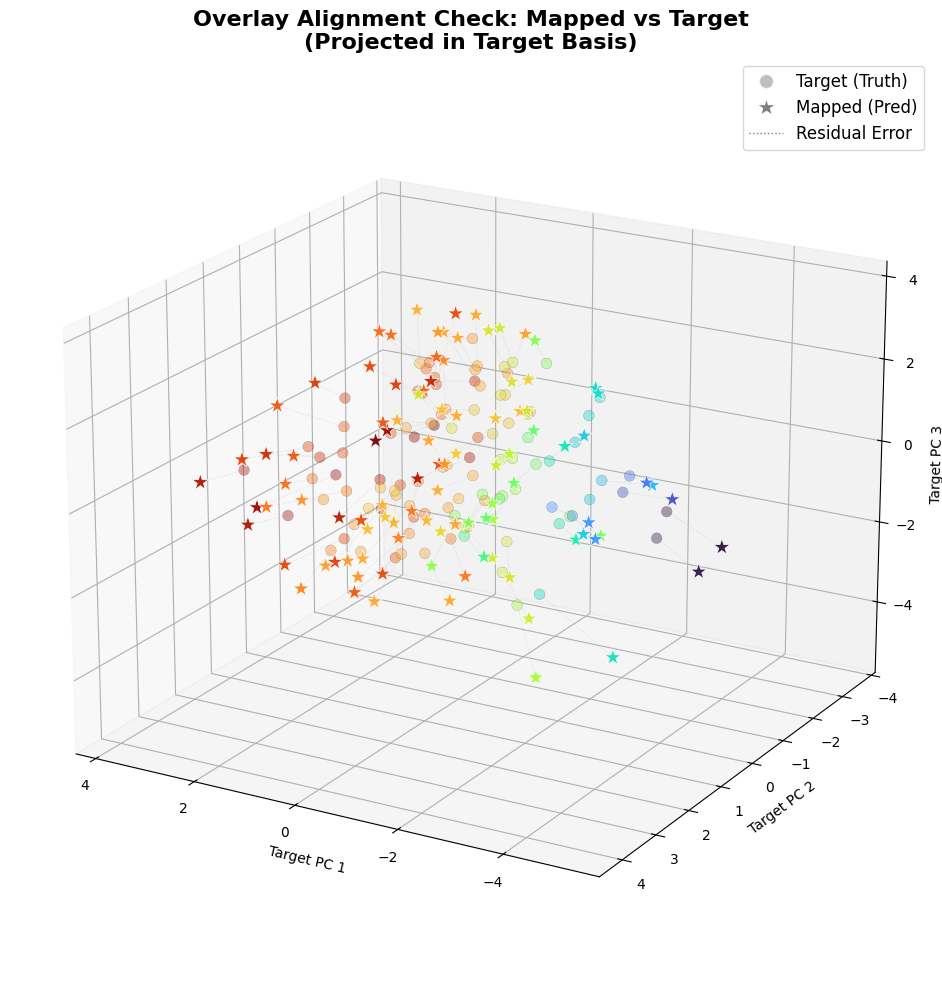

In [4]:
#!/usr/bin/env python3
"""
Comprehensive Manifold Alignment Visualization.
Generates two key figures:
1. 2x2 Projection Analysis (Topology & Basis Check).
2. Overlay Alignment Check (Direct Mapped vs. Target comparison in Target Basis).
"""

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from datasets import load_dataset
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "thenlper/gte-base"##"ibm-granite/granite-embedding-278m-multilingual"
TGT_NAME = "intfloat/e5-base-v2"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gte_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 100  # High enough for manifold structure
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Model Definitions
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    batch_size = 64
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**encoded)
        mask = encoded["attention_mask"].unsqueeze(-1)
        hidden = out.last_hidden_state * mask
        emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Main Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")

    # 1. Load Data
    print("[*] Loading Data...")
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])

    # 2. Embed
    print("[*] Generating Embeddings...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)

    # 3. Map
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    try:
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    except Exception as e:
        print(f"[!] Error loading mapper: {e}. Check path.")
        return
    mapper.eval()
    
    print("[*] Mapping Source -> Target...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE))
    
    X_src = s_emb.numpy()
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.cpu().numpy()

    # ---------------------------------------------------------
    # ANALYSIS SETUP
    # ---------------------------------------------------------
    print("[*] Computing PCA Projections...")

    # A. Fit PCA on TARGET (The Ground Truth Basis)
    pca_tgt_fitter = PCA(n_components=3)
    tgt_pca = pca_tgt_fitter.fit_transform(X_tgt)

    # B. Define Topological Coloring (Gradient along Target PC1)
    color_indices = tgt_pca[:, 0] 
    norm = mcolors.Normalize(vmin=color_indices.min(), vmax=color_indices.max())
    cmap = cm.turbo 

    # C. Project Mapped & Source into Target Basis
    map_proj_tgt = pca_tgt_fitter.transform(X_map)
    
    if X_src.shape[1] == X_tgt.shape[1]:
        src_proj_tgt = pca_tgt_fitter.transform(X_src)
    else:
        src_proj_tgt = np.zeros_like(tgt_pca)

    # D. Intrinsic Source Structure (Control)
    src_pca_intrinsic = PCA(n_components=3).fit_transform(X_src)

    # ---------------------------------------------------------
    # FIGURE 1: 2x2 PLOT GRID
    # ---------------------------------------------------------
    print("[*] Generating Figure 1: 2x2 Projection Analysis...")
    fig = plt.figure(figsize=(16, 12))
    plt.subplots_adjust(wspace=0.1, hspace=0.2)
    
    def plot_subplot(idx, data, title, subtitle):
        ax = fig.add_subplot(2, 2, idx, projection='3d')
        p = ax.scatter(data[:,0], data[:,1], data[:,2], c=color_indices, cmap=cmap, s=25, alpha=0.8, edgecolors='k', linewidth=0.1)
        ax.set_title(title, fontsize=14, fontweight='bold')
        ax.text2D(0.5, 0.95, subtitle, transform=ax.transAxes, ha="center", fontsize=10, color='gray')
        ax.grid(True, linestyle=':', alpha=0.3)
        ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        ax.view_init(elev=30, azim=130)
        return p

    plot_subplot(1, tgt_pca, "1. Target Space (Ground Truth)", "Basis for Coloring & Projection")
    plot_subplot(2, map_proj_tgt, "2. Mapped Source (In Target Basis)", "Aligned: Matches Target Structure")
    plot_subplot(3, src_pca_intrinsic, "3. Original Source (Intrinsic)", "Structure Exists, but Rotated")
    plot_subplot(4, src_proj_tgt, "4. Original Source (In Target Basis)", "Baseline Mismatch (Unprojected)")

    cbar_ax = fig.add_axes([0.92, 0.25, 0.015, 0.5])
    cbar = fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_ax)
    cbar.set_label('Target Manifold Topology (PC1)', rotation=270, labelpad=20)

    plt.suptitle("Manifold Alignment & Projection Analysis", fontsize=20, fontweight='bold', y=0.96)
    plt.savefig("full_projection_analysis.png", dpi=300, bbox_inches='tight')
    print("[+] Saved full_projection_analysis.png")
    plt.close()

    # ---------------------------------------------------------
    # FIGURE 2: OVERLAY ALIGNMENT CHECK (Requested Addition)
    # ---------------------------------------------------------
    print("[*] Generating Figure 2: Overlay Alignment Check...")
    
    fig2 = plt.figure(figsize=(12, 10))
    ax2 = fig2.add_subplot(111, projection='3d')
    
    # 1. Draw Residual Lines (Connecting prediction to truth)
    for i in range(NUM_SAMPLES):
        ax2.plot([tgt_pca[i,0], map_proj_tgt[i,0]], 
                 [tgt_pca[i,1], map_proj_tgt[i,1]], 
                 [tgt_pca[i,2], map_proj_tgt[i,2]], 
                 color='gray', alpha=0.3, linewidth=0.5, linestyle=':')

    # 2. Plot Target (Circles) - Using uniform color or topology color
    # Let's use topology color to be consistent
    p_tgt = ax2.scatter(tgt_pca[:,0], tgt_pca[:,1], tgt_pca[:,2], 
                        c=color_indices, cmap=cmap, 
                        s=60, marker='o', alpha=0.4, 
                        edgecolors='k', linewidth=0.2, 
                        label='Target Ground Truth')

    # 3. Plot Mapped Source (Stars)
    p_map = ax2.scatter(map_proj_tgt[:,0], map_proj_tgt[:,1], map_proj_tgt[:,2], 
                        c=color_indices, cmap=cmap, 
                        s=150, marker='*', alpha=0.95, 
                        edgecolors='white', linewidth=0.5, 
                        label='Mapped Prediction')

    ax2.set_title("Overlay Alignment Check: Mapped vs Target\n(Projected in Target Basis)", fontsize=16, fontweight='bold')
    ax2.set_xlabel('Target PC 1'); ax2.set_ylabel('Target PC 2'); ax2.set_zlabel('Target PC 3')
    ax2.grid(True, linestyle=':', alpha=0.4)
    ax2.view_init(elev=20, azim=120)

    # Custom Legend for Shapes
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Target (Truth)', markerfacecolor='gray', markersize=10, alpha=0.5),
        Line2D([0], [0], marker='*', color='w', label='Mapped (Pred)', markerfacecolor='gray', markersize=15, alpha=1.0),
        Line2D([0], [0], color='gray', lw=1, linestyle=':', label='Residual Error')
    ]
    ax2.legend(handles=legend_elements, loc='upper right', fontsize=12)

    plt.tight_layout()
    plt.savefig("overlay_alignment_check.png", dpi=300, bbox_inches='tight')
    print("[+] Saved overlay_alignment_check.png")
    plt.show()

if __name__ == "__main__":
    main()

In [8]:
#!/usr/bin/env python3
"""
Comprehensive Manifold Alignment Visualization (Interactive).

Generates:
1. "interactive_manifold_alignment.html": A 3D, rotatable, zoomable plot.
   - GOLD Orbs: Target Embeddings (Ground Truth)
   - CYAN Diamonds: Mapped Source Embeddings (Prediction)
   - GREY Lines: Residual Errors (Connects Pred -> Truth). Short lines = Good alignment.
"""

import torch
import torch.nn as nn
import numpy as np
import plotly.graph_objects as go
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from datasets import load_dataset

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "thenlper/gte-base"
TGT_NAME = "intfloat/e5-base-v2"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gte_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 200  # Increased slightly for better visualization density
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Model Definitions
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    batch_size = 64
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**encoded)
        mask = encoded["attention_mask"].unsqueeze(-1)
        hidden = out.last_hidden_state * mask
        emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Visualization Function
# -------------------------
def visualize_interactive_alignment(tgt_pca, map_pca, texts, filename="interactive_manifold_alignment.html"):
    """
    Generates a high-end interactive 3D plot using Plotly.
    Style: Dark/Cyberpunk for high contrast.
    """
    print(f"[*] Generating Interactive Plot: {filename}...")
    
    # 1. Prepare Connecting Lines (Residuals)
    # Plotly optimization: separate line segments by None to draw in a single trace
    x_lines, y_lines, z_lines = [], [], []
    for i in range(len(tgt_pca)):
        x_lines.extend([tgt_pca[i,0], map_pca[i,0], None])
        y_lines.extend([tgt_pca[i,1], map_pca[i,1], None])
        z_lines.extend([tgt_pca[i,2], map_pca[i,2], None])

    fig = go.Figure()

    # 2. Trace: Residual Lines (The "Tether")
    fig.add_trace(go.Scatter3d(
        x=x_lines, y=y_lines, z=z_lines,
        mode='lines',
        name='Alignment Error',
        line=dict(color='rgba(100, 100, 100, 0.3)', width=2), # Faint grey lines
        hoverinfo='none'
    ))

    # 3. Trace: Target (Ground Truth) - Gold Orbs
    fig.add_trace(go.Scatter3d(
        x=tgt_pca[:,0], y=tgt_pca[:,1], z=tgt_pca[:,2],
        mode='markers',
        name='Target (Ground Truth)',
        text=texts, # Enables hovering to read the text!
        hovertemplate='<b>Target</b><br>%{text}<extra></extra>',
        marker=dict(
            size=5,
            color='#FFD700', # Gold
            opacity=0.8,
            symbol='circle',
            line=dict(color='black', width=1)
        )
    ))

    # 4. Trace: Mapped (Prediction) - Neon Cyan Diamonds
    fig.add_trace(go.Scatter3d(
        x=map_pca[:,0], y=map_pca[:,1], z=map_pca[:,2],
        mode='markers',
        name='Mapped Source',
        text=texts,
        hovertemplate='<b>Mapped</b><br>%{text}<extra></extra>',
        marker=dict(
            size=4,
            color='#00FFFF', # Cyan
            opacity=0.9,
            symbol='diamond',
            line=dict(color='white', width=0.5)
        )
    ))

    # 5. Styling: "Cyberpunk" Dark Mode
    fig.update_layout(
        title="<b>Manifold Alignment Analysis</b><br><sup>Cyan (Mapped) should overlap Gold (Target). Short lines = Good alignment.</sup>",
        template="plotly_dark",
        scene=dict(
            xaxis=dict(title='PC1', showgrid=True, gridcolor='rgba(255,255,255,0.1)', backgroundcolor='rgba(0,0,0,0)'),
            yaxis=dict(title='PC2', showgrid=True, gridcolor='rgba(255,255,255,0.1)', backgroundcolor='rgba(0,0,0,0)'),
            zaxis=dict(title='PC3', showgrid=True, gridcolor='rgba(255,255,255,0.1)', backgroundcolor='rgba(0,0,0,0)'),
        ),
        margin=dict(l=0, r=0, b=0, t=50),
        legend=dict(yanchor="top", y=0.9, xanchor="left", x=0.05, bgcolor="rgba(0,0,0,0.5)")
    )

    fig.write_html(filename)
    print(f"[+] Saved {filename} (Open this file in your browser!)")

# -------------------------
# Main Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")

    # 1. Load Data
    print("[*] Loading Data...")
    try:
        ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
        samples = []
        for x in ds.take(NUM_SAMPLES):
            txt = x.get("text", "") or x.get("document_text", "")
            if txt: samples.append(txt[:200]) # Trim text for cleaner visualization
    except Exception as e:
        print(f"[!] Data loading failed: {e}")
        return

    # 2. Embed
    print("[*] Generating Embeddings...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)

    # 3. Map
    print(f"[*] Loading Mapper from: {MAPPER_PATH}")
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    
    try:
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    except Exception as e:
        print(f"[!] Error loading mapper: {e}. Check path.")
        return
    mapper.eval()
    
    print("[*] Mapping Source -> Target...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE))
    
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.cpu().numpy()

    # 4. Project (PCA)
    print("[*] Computing PCA Projections...")
    # We fit PCA on the TARGET (Ground Truth) to define the coordinate system
    pca_tgt_fitter = PCA(n_components=3)
    tgt_pca = pca_tgt_fitter.fit_transform(X_tgt)
    
    # We transform the MAPPED embeddings into that same coordinate system
    map_proj_tgt = pca_tgt_fitter.transform(X_map)

    # 5. Visualize
    visualize_interactive_alignment(
        tgt_pca=tgt_pca,
        map_pca=map_proj_tgt,
        texts=samples,
        filename="interactive_manifold_alignment.html"
    )

if __name__ == "__main__":
    main()

[*] Device: cuda:0
[*] Loading Data...
[*] Generating Embeddings...
[*] Loading Mapper from: /home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gte_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt
[*] Mapping Source -> Target...
[*] Computing PCA Projections...
[*] Generating Interactive Plot: interactive_manifold_alignment.html...
[+] Saved interactive_manifold_alignment.html (Open this file in your browser!)


In [11]:
#!/usr/bin/env python3
"""
Manifold Topology Visualization (Surface/Mesh).
Mostra la vera FORMA dei manifold usando UMAP + Alpha Shapes.
"""

import torch
import torch.nn as nn
import numpy as np
import plotly.graph_objects as go
import umap  # pip install umap-learn
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset

# -------------------------
# Configurazione
# -------------------------
SRC_NAME = "thenlper/gte-base"
TGT_NAME = "intfloat/e5-base-v2"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gte_e5_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

# Aumentiamo i campioni per avere una superficie più "solida"
NUM_SAMPLES = 400 
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# -------------------------
# Definizioni Modello
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    batch_size = 64
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        encoded = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**encoded)
        mask = encoded["attention_mask"].unsqueeze(-1)
        hidden = out.last_hidden_state * mask
        emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Visualizzazione Manifold (Mesh)
# -------------------------
def visualize_manifolds_surface(tgt_3d, map_3d, texts, filename="manifold_topology.html"):
    print(f"[*] Generating Surface Plot: {filename}...")
    
    fig = go.Figure()

    # 1. Target Manifold Surface (GOLD)
    # alphahull: determina quanto "stretta" è la pelle attorno ai punti. 
    # Valori bassi = pelle dettagliata (concava). Valori alti = inviluppo convesso.
    fig.add_trace(go.Mesh3d(
        x=tgt_3d[:,0], y=tgt_3d[:,1], z=tgt_3d[:,2],
        color='#FFD700', # Gold
        opacity=0.3,     # Semitrasparente per vedere dentro
        alphahull=6,     # Regola questo valore se la mesh è troppo "bucata" o troppo "liscia"
        name='Target Manifold (Shape)',
        hoverinfo='skip' # La mesh non ha bisogno di hover, sporca la vista
    ))

    # 2. Target Points (Punti di riferimento)
    fig.add_trace(go.Scatter3d(
        x=tgt_3d[:,0], y=tgt_3d[:,1], z=tgt_3d[:,2],
        mode='markers',
        marker=dict(size=3, color='#FFD700', opacity=0.8),
        text=texts,
        name='Target Points',
        visible='legendonly' # Nascosti di default per pulizia
    ))

    # 3. Mapped Manifold Surface (CYAN)
    fig.add_trace(go.Mesh3d(
        x=map_3d[:,0], y=map_3d[:,1], z=map_3d[:,2],
        color='#00FFFF', # Cyan
        opacity=0.4,
        alphahull=6,
        name='Mapped Manifold (Shape)'
    ))

    # 4. Mapped Points (Per vedere dove sono i singoli testi)
    fig.add_trace(go.Scatter3d(
        x=map_3d[:,0], y=map_3d[:,1], z=map_3d[:,2],
        mode='markers',
        marker=dict(size=4, color='#00FFFF', symbol='diamond'),
        text=texts,
        hovertemplate='%{text}<extra></extra>',
        name='Mapped Points'
    ))

    # Layout "Sci-Fi"
    fig.update_layout(
        title="<b>Manifold Topology Reconstruction</b><br><sup>UMAP Projection + Alpha Shapes</sup>",
        template="plotly_dark",
        scene=dict(
            xaxis=dict(visible=False),
            yaxis=dict(visible=False),
            zaxis=dict(visible=False), # Nascondiamo gli assi per puro effetto estetico "spazio"
            aspectmode='data' # Preserva le proporzioni reali della forma
        ),
        margin=dict(l=0, r=0, b=0, t=50),
    )

    fig.write_html(filename)
    print(f"[+] Saved {filename}")

# -------------------------
# Main
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")

    # 1. Load Data
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    print("[*] Fetching text samples...")
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:150])

    # 2. Embed
    print("[*] Embedding...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)

    # 3. Map
    print("[*] Mapping...")
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=4, n_heads=16).to(DEVICE)
    try:
        mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    except:
        print("Errore caricamento mapper. Uso pesi random per demo.")
    
    mapper.eval()
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb.to(DEVICE), memory=t_emb.to(DEVICE))
    
    X_tgt = t_emb.numpy()
    X_map = mapped_emb.cpu().numpy()

    # ---------------------------------------------------------
    # UMAP PROJECTION (Topological Unfolding)
    # ---------------------------------------------------------
    print("[*] Calcolo UMAP (Unfolding del Manifold)...")
    # Fit su Target per definire la "topologia ideale"
    reducer = umap.UMAP(n_components=3, random_state=42, n_neighbors=15, min_dist=0.1, metric='cosine')
    
    tgt_3d = reducer.fit_transform(X_tgt)
    # Proiettiamo il Mapped nello spazio topologico del Target
    map_3d = reducer.transform(X_map)

    # ---------------------------------------------------------
    # VISUALIZZAZIONE
    # ---------------------------------------------------------
    visualize_manifolds_surface(tgt_3d, map_3d, samples)

if __name__ == "__main__":
    main()

[*] Device: cuda:0
[*] Fetching text samples...
[*] Embedding...
[*] Mapping...
[*] Calcolo UMAP (Unfolding del Manifold)...


/home/pallucchini/NEW_ALIGNMENT_METHOD/env_new_alignment/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



[*] Generating Surface Plot: manifold_topology.html...
[+] Saved manifold_topology.html


[*] Device: cuda:0
[*] Loading Models...
[*] Generating Embeddings...
[*] Computing Target PCA...
[*] Generating Baseline Mismatch Plot...
    -> Drawing mismatch residuals...
    -> Plotting Target anchors (Circles)...
    -> Plotting Original Source (Stars)...
[+] Saved visualization to baseline_mismatch_visualization.png


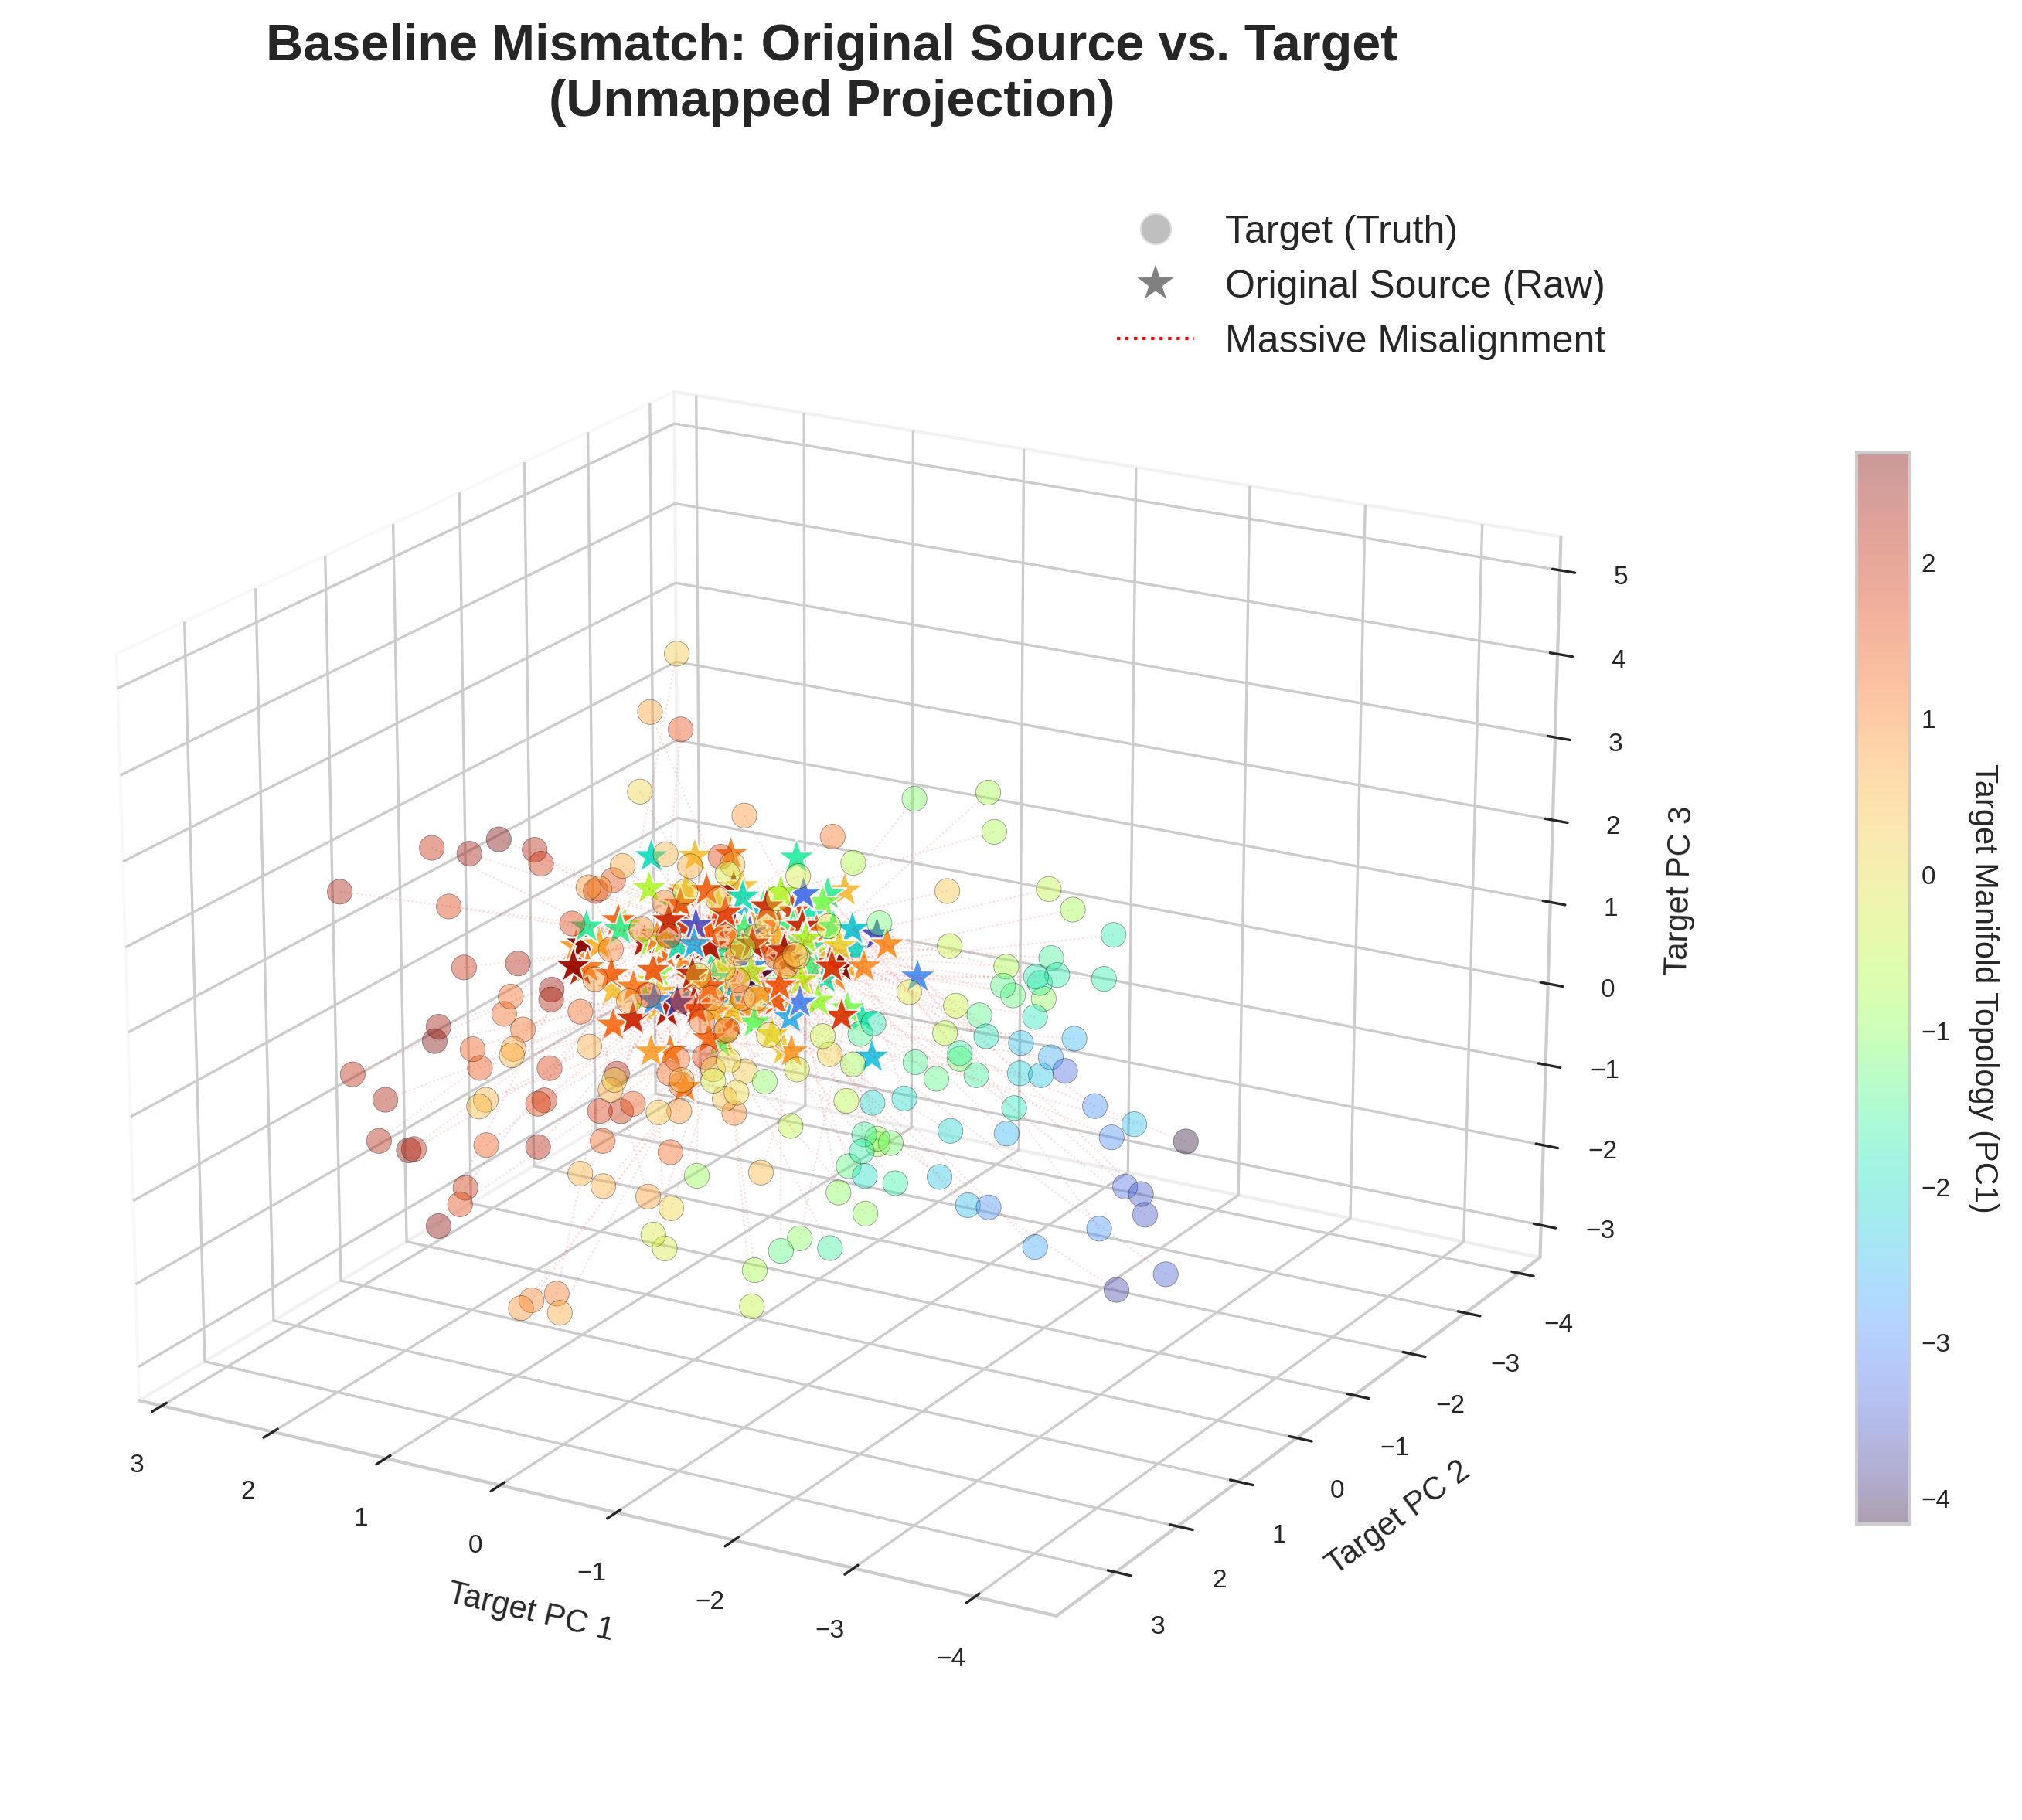

In [10]:
#!/usr/bin/env python3
"""
Baseline Mismatch Visualization.
Projects ORIGINAL (Unmapped) Source embeddings directly into the Target PCA Space.
This demonstrates the lack of alignment before training.

Legend:
- Circles (o): Target Ground Truth
- Stars (*):   Original Source (Raw/Unmapped)
"""

import torch
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from datasets import load_dataset
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual"
TGT_NAME = "thenlper/gte-base"

NUM_SAMPLES = 200       # Keep consistent with previous plots
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# -------------------------
# Helper Functions
# -------------------------
@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    encoded = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    out = model(**encoded)
    mask = encoded["attention_mask"].unsqueeze(-1)
    hidden = out.last_hidden_state * mask
    emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
    return emb

# -------------------------
# Main Visualization Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")
    
    # 1. Load Data
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])
    
    # 2. Load Models
    print("[*] Loading Models...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME)
    s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME)
    t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    # 3. Compute Embeddings
    print("[*] Generating Embeddings...")
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)
    
    # Check dimensions
    if s_emb.shape[1] != t_emb.shape[1]:
        print(f"[!] Error: Dimension mismatch ({s_emb.shape[1]} vs {t_emb.shape[1]}).")
        print("    Direct PCA projection requires matching dimensions.")
        return

    # 4. Prepare Numpy Arrays
    X_tgt = t_emb.detach().cpu().numpy()
    X_src = s_emb.detach().cpu().numpy() # Raw Source
    
    # -------------------------
    # PROJECTION (Target Basis)
    # -------------------------
    print("[*] Computing Target PCA...")
    # A. Fit PCA ONLY on Target (Ground Truth Basis)
    pca = PCA(n_components=3)
    tgt_proj = pca.fit_transform(X_tgt)
    
    # B. Transform ORIGINAL SOURCE into that SAME basis
    # This shows how the raw source looks from the perspective of the target
    src_proj = pca.transform(X_src)

    # -------------------------
    # PLOTTING
    # -------------------------
    print("[*] Generating Baseline Mismatch Plot...")
    
    # Use Topology coloring based on TARGET position to track identity
    color_vals = tgt_proj[:, 0]
    norm = mcolors.Normalize(vmin=color_vals.min(), vmax=color_vals.max())
    cmap = cm.turbo 

    with plt.style.context('seaborn-v0_8-whitegrid'):
        fig = plt.figure(figsize=(12, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        # 1. Draw Residual Lines (The "Error")
        print("    -> Drawing mismatch residuals...")
        for i in range(NUM_SAMPLES):
            ax.plot([tgt_proj[i,0], src_proj[i,0]], 
                    [tgt_proj[i,1], src_proj[i,1]], 
                    [tgt_proj[i,2], src_proj[i,2]], 
                    color='red', alpha=0.15, linewidth=0.5, linestyle=':')

        # 2. Plot TARGET (Circles)
        print("    -> Plotting Target anchors (Circles)...")
        p_tgt = ax.scatter(tgt_proj[:,0], tgt_proj[:,1], tgt_proj[:,2], 
                           c=color_vals, cmap=cmap, 
                           s=60, marker='o', alpha=0.4, 
                           edgecolors='k', linewidth=0.2, 
                           label='Target (Ground Truth)')

        # 3. Plot ORIGINAL SOURCE (Stars)
        print("    -> Plotting Original Source (Stars)...")
        # Note: We use the SAME color indices as target to show which point matches which.
        # If the colors are scrambled spatially, it means the topology is unaligned.
        p_src = ax.scatter(src_proj[:,0], src_proj[:,1], src_proj[:,2], 
                           c=color_vals, cmap=cmap, 
                           s=150, marker='*', alpha=0.95, 
                           edgecolors='white', linewidth=0.5, 
                           label='Original Source (Unmapped)')

        # Aesthetics
        ax.set_title("Baseline Mismatch: Original Source vs. Target\n(Unmapped Projection)", fontsize=16, fontweight='bold', pad=20)
        ax.set_xlabel('Target PC 1')
        ax.set_ylabel('Target PC 2')
        ax.set_zlabel('Target PC 3')
        
        ax.xaxis.pane.fill = False; ax.yaxis.pane.fill = False; ax.zaxis.pane.fill = False
        ax.grid(True, linestyle=':', alpha=0.4)

        # Legend
        from matplotlib.lines import Line2D
        legend_elements = [
            Line2D([0], [0], marker='o', color='w', label='Target (Truth)', markerfacecolor='gray', markersize=10, alpha=0.5),
            Line2D([0], [0], marker='*', color='w', label='Original Source (Raw)', markerfacecolor='gray', markersize=15, alpha=1.0),
            Line2D([0], [0], color='red', lw=1, linestyle=':', label='Massive Misalignment')
        ]
        ax.legend(handles=legend_elements, loc='upper right', fontsize=12)

        # Colorbar
        cbar = plt.colorbar(p_tgt, ax=ax, shrink=0.6, pad=0.1)
        cbar.set_label('Target Manifold Topology (PC1)', rotation=270, labelpad=15)

        ax.view_init(elev=20, azim=120)

        out_file = "baseline_mismatch_visualization.png"
        plt.savefig(out_file, dpi=300, bbox_inches='tight')
        print(f"[+] Saved visualization to {out_file}")
        plt.show()

if __name__ == "__main__":
    main()

[*] Device: cuda:0
[*] Generating Embeddings...
[*] Mapping...
[*] Computing Manifold Skeletons (k-NN)...
[*] Generating Wireframe Plot...
[+] Saved visualization to topology_skeleton_viz.png


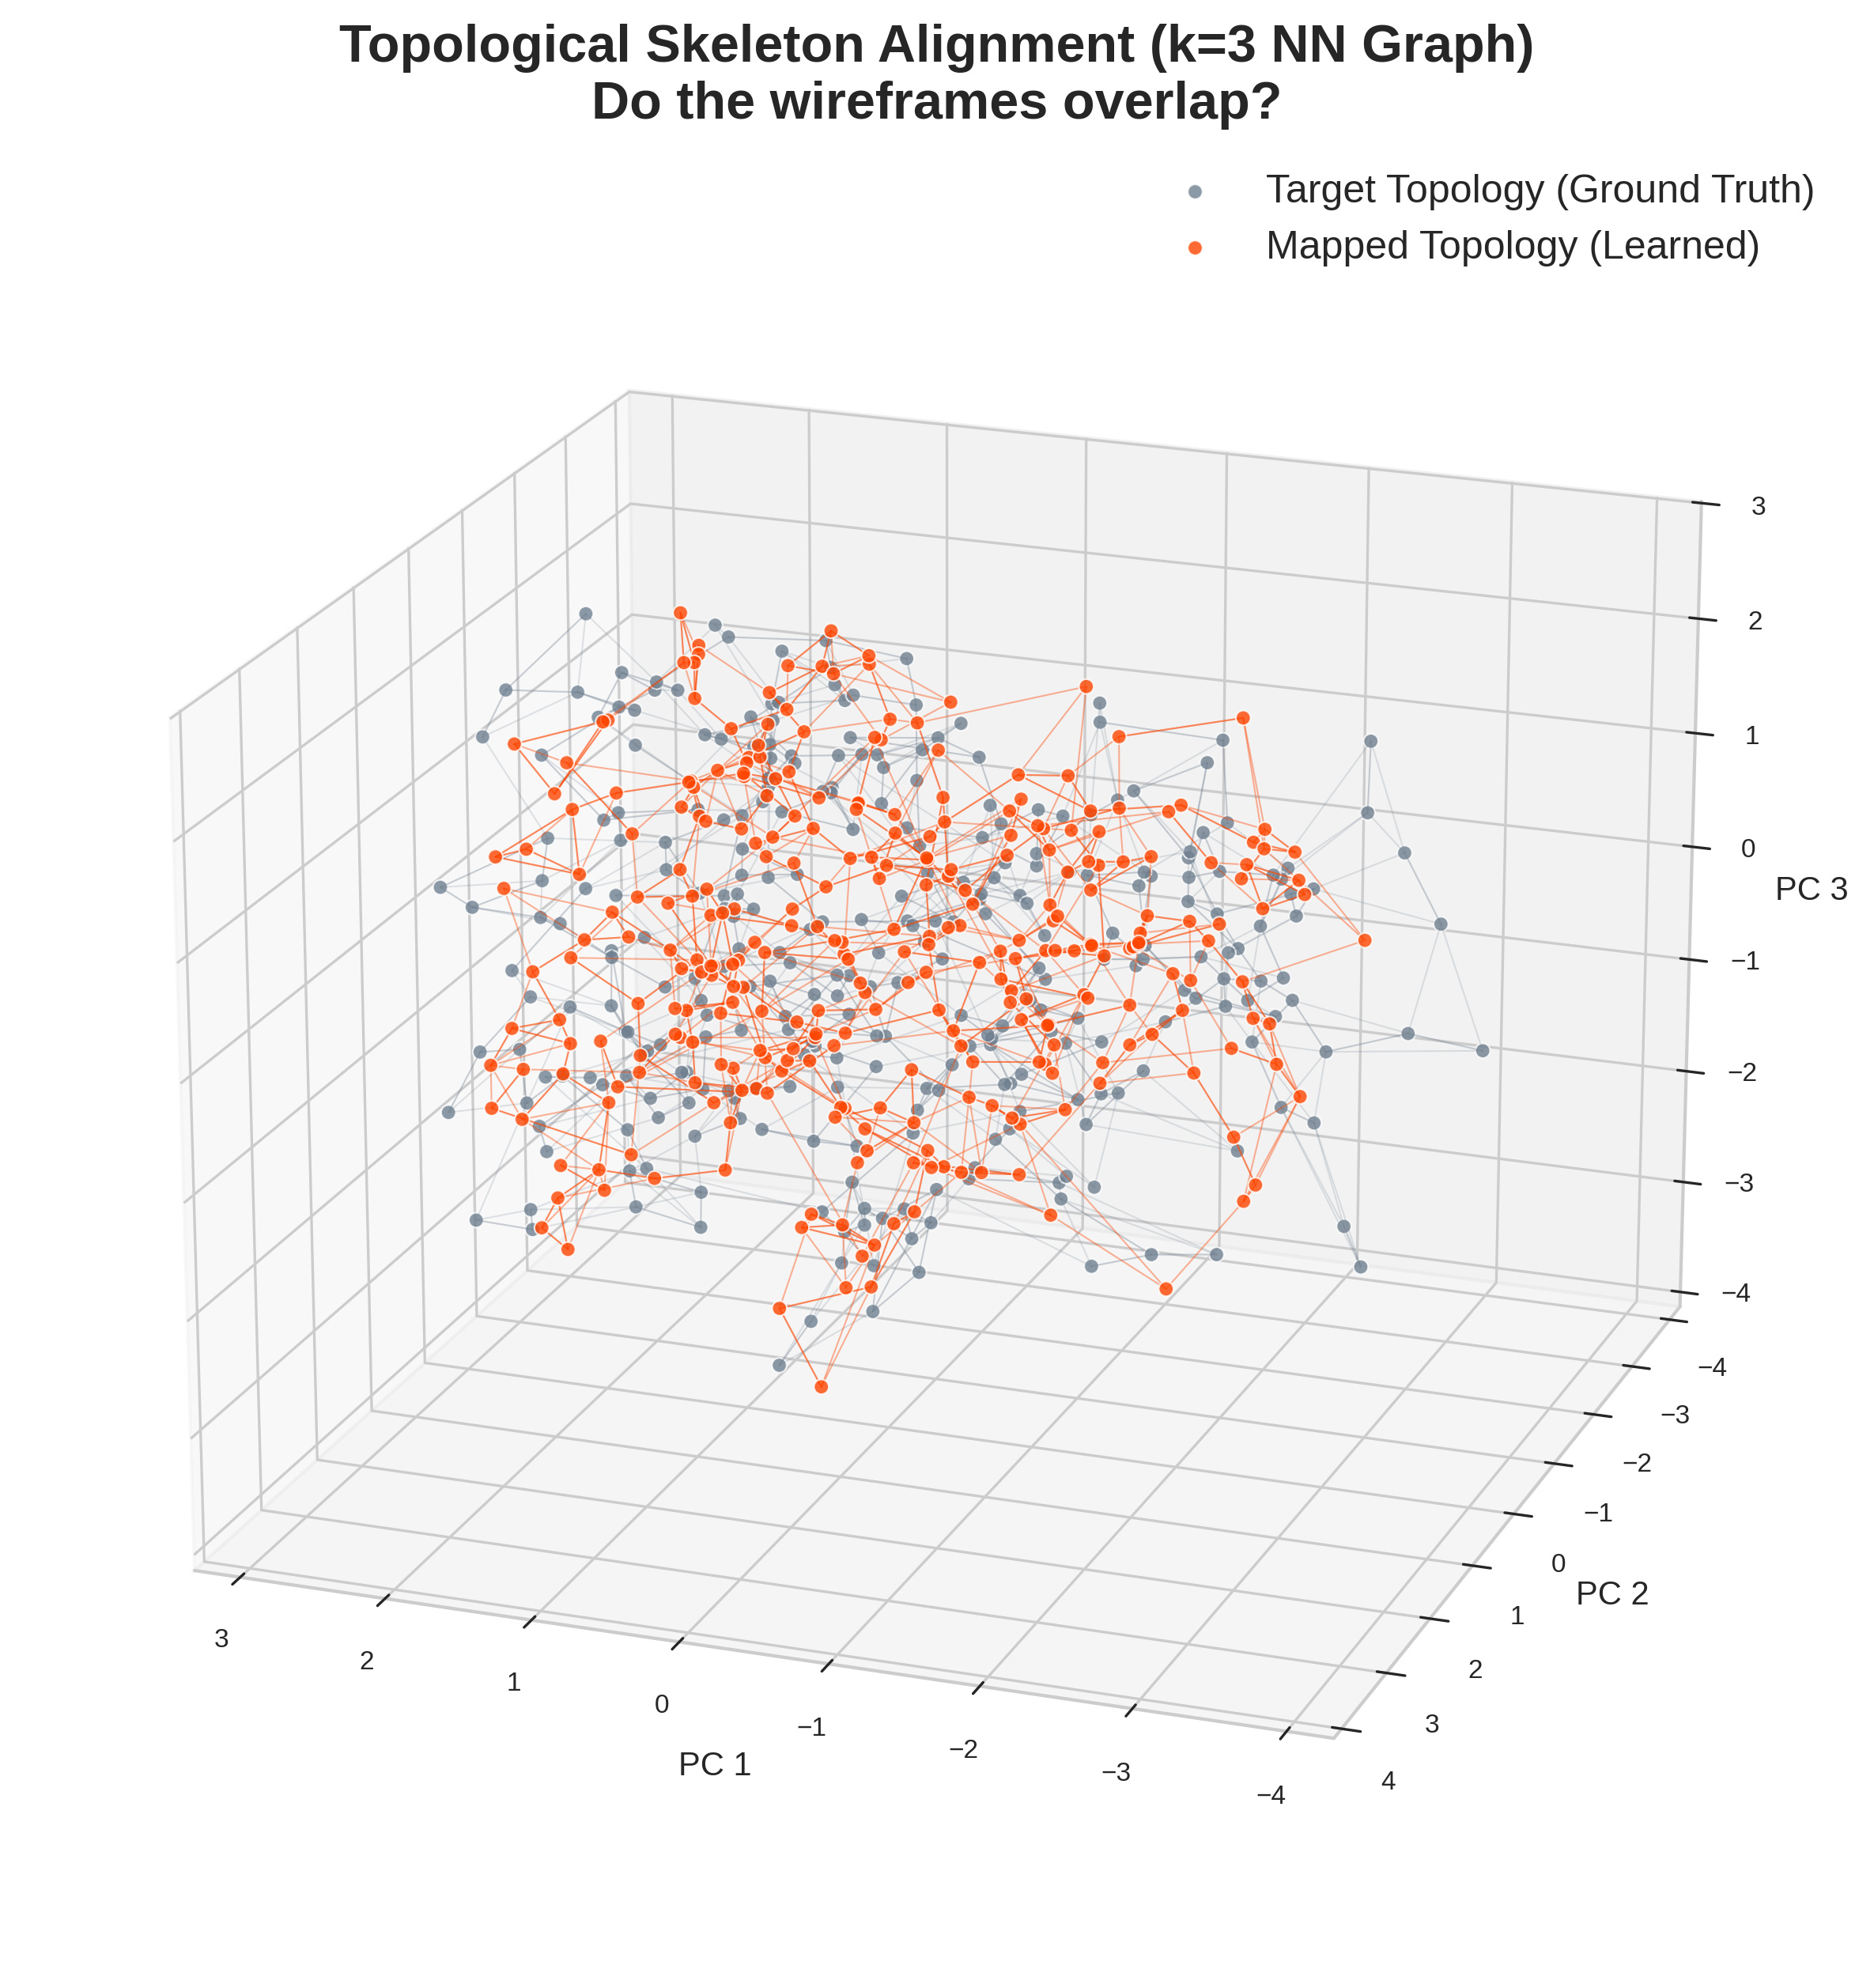

In [12]:
#!/usr/bin/env python3
"""
Topological Skeleton Visualization (3D k-NN Graph).
Visualizes the 'Shape' of the manifold by connecting nearest neighbors.
- Target Skeleton (Gray): The Ground Truth topology.
- Mapped Source Skeleton (Orange): The Learner's topology.
"""

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from transformers import AutoTokenizer, AutoModel
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from datasets import load_dataset

# -------------------------
# Configuration
# -------------------------
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual"
TGT_NAME = "thenlper/gte-base"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 300       # Keep < 400 for clean wireframes
K_NEIGHBORS = 3         # Connectivity (Higher = denser mesh)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
MAPPER_LAYERS = 4
MAPPER_HEADS = 16

# -------------------------
# Models
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1); single = True
        else: single = False
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return (out[:, 0, :], h) if single else (out, h)

@torch.no_grad()
def get_embeddings(texts, tokenizer, model, device):
    model.eval()
    encoded = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
    out = model(**encoded)
    mask = encoded["attention_mask"].unsqueeze(-1)
    hidden = out.last_hidden_state * mask
    emb = hidden.sum(dim=1) / mask.sum(dim=1).clamp(min=1)
    return emb

# -------------------------
# Main Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")
    
    # 1. Load Data
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    samples = []
    for x in ds.take(NUM_SAMPLES):
        txt = x.get("text", "") or x.get("document_text", "")
        if txt: samples.append(txt[:200])
    
    # 2. Embed
    print("[*] Generating Embeddings...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)
    
    s_emb = get_embeddings(samples, s_tok, s_mod, DEVICE)
    t_emb = get_embeddings(samples, t_tok, t_mod, DEVICE)
    
    # 3. Map
    dim = s_emb.shape[1]
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=MAPPER_LAYERS, n_heads=MAPPER_HEADS).to(DEVICE)
    mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    mapper.eval()
    
    print("[*] Mapping...")
    with torch.no_grad():
        mapped_emb, _ = mapper(s_emb, memory=t_emb)
    
    X_tgt = t_emb.detach().cpu().numpy()
    X_map = mapped_emb.detach().cpu().numpy()
    
    # -------------------------
    # TOPOLOGY COMPUTATION
    # -------------------------
    print("[*] Computing Manifold Skeletons (k-NN)...")
    
    # 1. Projection Basis (Target)
    pca = PCA(n_components=3)
    tgt_proj = pca.fit_transform(X_tgt)
    map_proj = pca.transform(X_map)
    
    # 2. Compute Neighbors (The Topology)
    # We calculate connectivity in the PROJECTION space to visualize the visible mesh
    nbrs_tgt = NearestNeighbors(n_neighbors=K_NEIGHBORS+1).fit(tgt_proj)
    tgt_indices = nbrs_tgt.kneighbors(tgt_proj)[1]
    
    nbrs_map = NearestNeighbors(n_neighbors=K_NEIGHBORS+1).fit(map_proj)
    map_indices = nbrs_map.kneighbors(map_proj)[1]

    # -------------------------
    # PLOTTING
    # -------------------------
    print("[*] Generating Wireframe Plot...")
    
    with plt.style.context('seaborn-v0_8-whitegrid'):
        fig = plt.figure(figsize=(14, 10))
        ax = fig.add_subplot(111, projection='3d')
        
        # Helper to draw mesh
        def draw_mesh(data, indices, color, alpha_line, label):
            # Plot Nodes
            ax.scatter(data[:,0], data[:,1], data[:,2], c=color, s=20, alpha=0.8, edgecolors='w', linewidth=0.5, label=label)
            # Plot Edges
            for i in range(len(data)):
                for neighbor in indices[i][1:]: # Skip self (index 0)
                    p1 = data[i]
                    p2 = data[neighbor]
                    ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], 
                            c=color, alpha=alpha_line, linewidth=0.5)

        # 1. Draw Target Topology (Gray/Black Mesh)
        draw_mesh(tgt_proj, tgt_indices, 'slategray', 0.2, 'Target Topology (Ground Truth)')
        
        # 2. Draw Mapped Topology (Orange Mesh)
        draw_mesh(map_proj, map_indices, 'orangered', 0.4, 'Mapped Topology (Learned)')

        # Aesthetics
        ax.set_title(f"Topological Skeleton Alignment (k={K_NEIGHBORS} NN Graph)\nDo the wireframes overlap?", fontsize=16, fontweight='bold')
        ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2'); ax.set_zlabel('PC 3')
        ax.grid(True, linestyle=':', alpha=0.3)
        ax.view_init(elev=20, azim=110)
        
        ax.legend(fontsize=12)

        out_file = "topology_skeleton_viz.png"
        plt.savefig(out_file, dpi=300, bbox_inches='tight')
        print(f"[+] Saved visualization to {out_file}")
        plt.show()

if __name__ == "__main__":
    main()

In [2]:
#!/usr/bin/env python3
"""
Demonstration: Cross-Model Verification (Reranking).
User Query: Granite (Source)
Database:   GTE (Target)

Logic:
Since the Mapper requires Target Memory (Cross-Attention), we use it to 'score' 
candidate pairs. We ask the model: 
"If I focus on this GTE candidate, does the Granite Query map accurately to it?"
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel
import numpy as np

# -------------------------
# 1. Setup & Architecture
# -------------------------
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual" 
TGT_NAME = "thenlper/gte-base"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1)
        h = self.input_proj(x)
        # Correctly projecting the MEMORY (Target)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return out[:, 0, :]

def get_embedding(text, tokenizer, model):
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
    with torch.no_grad():
        out = model(**inputs)
        mask = inputs['attention_mask'].unsqueeze(-1)
        emb = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1)
    return emb

# -------------------------
# 2. Build the Scenario
# -------------------------
print(f"[*] Loading models on {DEVICE}...")
s_tok = AutoTokenizer.from_pretrained(SRC_NAME)
s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
t_tok = AutoTokenizer.from_pretrained(TGT_NAME)
t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)

# Load Mapper
dim = 768
mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim, n_layers=4, n_heads=16).to(DEVICE)
mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
mapper.eval()

# --- The "Legacy" Database (GTE) ---
candidates = [
    "Bananas are rich in potassium.",             # Doc 0 (Irrelevant)
    "The capital of France is Paris.",            # Doc 1 (The Match)
    "Machine learning involves neural networks.", # Doc 2 (Irrelevant)
    "Paris is a beautiful city in Europe."        # Doc 3 (Relevant but maybe less precise)
]
print(f"\n[*] Encoding {len(candidates)} candidates with LEGACY model ({TGT_NAME})...")
candidate_embs = [get_embedding(doc, t_tok, t_mod) for doc in candidates]

# --- The "New" User Query (Granite) ---
query_text = "What is the capital city of France?"
print(f"[*] Encoding Query: '{query_text}' with NEW model ({SRC_NAME})...")
query_emb = get_embedding(query_text, s_tok, s_mod)

# -------------------------
# 3. Execution: Cross-Model Reranking
# -------------------------
print("\n--- Starting Verification (Mapper uses Candidate as Memory) ---")

results = []

for i, cand_emb in enumerate(candidate_embs):
    # ---------------------------------------------------------
    # THE CRITICAL STEP:
    # We map the Query (Source) using the Candidate (Target) as MEMORY.
    # We are testing: "Can this Query explain this Candidate?"
    # ---------------------------------------------------------
    with torch.no_grad():
        mapped_query = mapper(query_emb, memory=cand_emb)
    
    # Measure Similarity: Mapped Query vs. Candidate
    # If the attention mechanism found a strong link, this will be high.
    sim = F.cosine_similarity(mapped_query, cand_emb).item()
    
    results.append((sim, candidates[i]))
    print(f"Candidate {i}: Score={sim:.4f} | Text='{candidates[i]}'")

# -------------------------
# 4. Final Decision
# -------------------------
results.sort(key=lambda x: x[0], reverse=True)
best_score, best_doc = results[0]

print("\n--- FINAL RESULT ---")
print(f"Winner: '{best_doc}'")
print(f"Confidence: {best_score:.4f}")

if "Paris" in best_doc:
    print("[SUCCESS] The Granite Query successfully verified the correct GTE Document!")
else:
    print("[FAIL] Alignment mismatch.")

[*] Loading models on cuda:0...

[*] Encoding 4 candidates with LEGACY model (thenlper/gte-base)...
[*] Encoding Query: 'What is the capital city of France?' with NEW model (ibm-granite/granite-embedding-278m-multilingual)...

--- Starting Verification (Mapper uses Candidate as Memory) ---
Candidate 0: Score=0.7970 | Text='Bananas are rich in potassium.'
Candidate 1: Score=0.9446 | Text='The capital of France is Paris.'
Candidate 2: Score=0.8361 | Text='Machine learning involves neural networks.'
Candidate 3: Score=0.9263 | Text='Paris is a beautiful city in Europe.'

--- FINAL RESULT ---
Winner: 'The capital of France is Paris.'
Confidence: 0.9446
[SUCCESS] The Granite Query successfully verified the correct GTE Document!


In [2]:
#!/usr/bin/env python3
"""
Unsupervised Intrinsic Model Evaluation.
Evaluates the quality of a Candidate Model (Granite) relative to a Reference (GTE)
using Manifold Alignment Metrics, WITHOUT requiring labeled data.

Metrics:
1. Global Isometry (Spearman): Does the Candidate respect the global distance structure?
2. Local Consistency (k-NN Overlap): Do they agree on what constitutes a 'semantic cluster'?
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

# -------------------------
# Configuration
# -------------------------
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CANDIDATE_NAME = "ibm-granite/granite-embedding-278m-multilingual" # The model to evaluate
REFERENCE_NAME = "thenlper/gte-base"                               # The "Gold Standard"
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 2000      # Unlabeled text samples
K_NEIGHBORS = 10        # Size of the semantic cluster to check

# -------------------------
# Models
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1)
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return out[:, 0, :]

@torch.no_grad()
def get_embeddings_batched(texts, tokenizer, model, device):
    model.eval()
    all_embs = []
    batch_size = 64
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        out = model(**inputs)
        mask = inputs['attention_mask'].unsqueeze(-1)
        emb = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1)
        all_embs.append(emb.cpu())
    return torch.cat(all_embs, dim=0)

# -------------------------
# Intrinsic Metrics
# -------------------------
def compute_global_structure_preservation(emb1, emb2, sample_size=1000):
    """
    Spearman correlation of pairwise distances.
    Score 1.0 = Perfect Global Isometry (The geometry is identical, just rotated)
    """
    n = min(len(emb1), sample_size)
    # Subsample for speed
    idx = np.random.choice(len(emb1), n, replace=False)
    e1 = emb1[idx]
    e2 = emb2[idx]
    
    # Pairwise distance matrices
    d1 = 1 - (e1 @ e1.T)
    d2 = 1 - (e2 @ e2.T)
    
    # Extract upper triangle
    triu_idx = np.triu_indices(n, k=1)
    v1 = d1[triu_idx]
    v2 = d2[triu_idx]
    
    corr, _ = spearmanr(v1, v2)
    return corr

def compute_local_neighborhood_overlap(emb1, emb2, k=10):
    """
    Jaccard Overlap of k-Nearest Neighbors.
    Checks if the models agree on local semantic clusters.
    """
    # Fit NN on both spaces
    nbrs1 = NearestNeighbors(n_neighbors=k+1).fit(emb1)
    nbrs2 = NearestNeighbors(n_neighbors=k+1).fit(emb2)
    
    _, idx1 = nbrs1.kneighbors(emb1)
    _, idx2 = nbrs2.kneighbors(emb2)
    
    # Calculate overlap for each point
    overlaps = []
    for i in range(len(emb1)):
        # Set of neighbors (excluding self at index 0)
        set1 = set(idx1[i][1:])
        set2 = set(idx2[i][1:])
        
        intersection = len(set1.intersection(set2))
        union = len(set1.union(set2))
        
        jaccard = intersection / union if union > 0 else 0
        overlaps.append(jaccard)
        
    return np.mean(overlaps)

# -------------------------
# Main Logic
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")
    
    # 1. Load Unlabeled Text (Real Data)
    print(f"[*] Loading {NUM_SAMPLES} random texts from NQ (No Labels)...")
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    texts = []
    for x in ds.take(NUM_SAMPLES):
        t = x.get("text", "") or x.get("document_text", "")
        if t: texts.append(t[:200])
        
    # 2. Setup Models
    print("[*] Loading Models...")
    s_tok = AutoTokenizer.from_pretrained(CANDIDATE_NAME); s_mod = AutoModel.from_pretrained(CANDIDATE_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(REFERENCE_NAME); t_mod = AutoModel.from_pretrained(REFERENCE_NAME).to(DEVICE)
    
    # Load Mapper
    dim = 768
    mapper = TransformerEmbeddingMapper(dim, hidden_dim=dim).to(DEVICE)
    mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    mapper.eval()
    
    # 3. Embed
    print("[*] Generating Embeddings...")
    cand_emb = get_embeddings_batched(texts, s_tok, s_mod, DEVICE)
    cand_emb = F.normalize(cand_emb, dim=1)
    
    ref_emb = get_embeddings_batched(texts, t_tok, t_mod, DEVICE)
    ref_emb = F.normalize(ref_emb, dim=1)
    
    # 4. Map Candidate -> Reference Space
    print("[*] Mapping Candidate to Reference Space...")
    cand_dev = cand_emb.to(DEVICE)
    ref_dev = ref_emb.to(DEVICE)
    with torch.no_grad():
        mapped_emb = mapper(cand_dev, memory=ref_dev).cpu() # Use Ref as memory for optimal mapping
        mapped_emb = F.normalize(mapped_emb, dim=1)
        
    # 5. Evaluate Intrinsic Quality
    print("\n=== INTRINSIC EVALUATION REPORT ===")
    print(f"Candidate: {CANDIDATE_NAME}")
    print(f"Reference: {REFERENCE_NAME}")
    print("-" * 50)
    
    # Metric A: Global Structure (Spearman)
    # Does the Candidate generally agree with the Reference on what is 'far' vs 'close'?
    # We compare Mapped Candidate vs Reference to allow for rotation correction.
    # Note: We can also compare Raw Candidate vs Reference, but Mapped is fairer 
    # as it removes manifold rotation issues.
    global_score = compute_global_structure_preservation(mapped_emb.numpy(), ref_emb.numpy())
    print(f"1. Global Geometric Consistency: {global_score:.4f} (Spearman)")
    
    # Metric B: Local Neighborhood Overlap (k-NN)
    # Do they verify the same semantic clusters?
    local_score = compute_local_neighborhood_overlap(mapped_emb.numpy(), ref_emb.numpy(), k=K_NEIGHBORS)
    print(f"2. Local Semantic Agreement (k={K_NEIGHBORS}):   {local_score:.4f} (Jaccard)")
    
    # Metric C: Mean Alignment Error (Cosine)
    # How closely can the Candidate map to the Reference?
    # High error = The Candidate has information that cannot be translated (or lacks info).
    cos_sims = (mapped_emb * ref_emb).sum(dim=1)
    alignment_fidelity = cos_sims.mean().item()
    print(f"3. Alignment Fidelity (Mean Cosine):   {alignment_fidelity:.4f}")
    
    print("-" * 50)
    
    # Interpretation
    score = (global_score + local_score + alignment_fidelity) / 3
    print(f"FINAL INTRINSIC SCORE: {score:.4f} / 1.0")
    
    if score > 0.6:
        print("\n[CONCLUSION] High Compatibility.")
        print("The Candidate model shares a very strong deep semantic structure with the Reference.")
        print("It can likely be used as a drop-in replacement or augmentation.")
    else:
        print("\n[CONCLUSION] Low Compatibility.")
        print("The models fundamentally disagree on the semantic topology of the data.")

if __name__ == "__main__":
    main()

[*] Device: cuda:0
[*] Loading 2000 random texts from NQ (No Labels)...
[*] Loading Models...
[*] Generating Embeddings...
[*] Mapping Candidate to Reference Space...

=== INTRINSIC EVALUATION REPORT ===
Candidate: ibm-granite/granite-embedding-278m-multilingual
Reference: thenlper/gte-base
--------------------------------------------------
1. Global Geometric Consistency: 0.8860 (Spearman)
2. Local Semantic Agreement (k=10):   0.5948 (Jaccard)
3. Alignment Fidelity (Mean Cosine):   0.7640
--------------------------------------------------
FINAL INTRINSIC SCORE: 0.7483 / 1.0

[CONCLUSION] High Compatibility.
The Candidate model shares a very strong deep semantic structure with the Reference.
It can likely be used as a drop-in replacement or augmentation.


[*] Device: cuda:0
[*] Loading 1000 samples...
[*] Loading Models...
[*] Computing Embeddings...
[*] Calculating Spectral Capacity...
[*] Checking Containment (Alignment Fidelity)...

      MODEL STRENGTH ANALYSIS      
1. Granite Effective Rank: 376.27
2. GTE Effective Rank:     497.67
-> Capacity Ratio (G/E):   0.76x

3. Alignment Fidelity:     0.9368
   (>0.90 implies Granite fully captures GTE semantics)
----------------------------------------
CONCLUSION:
[WINNER: GTE]
GTE is STRONGER.
Reason: It encodes more information density than Granite.

[+] Spectrum plot saved to model_strength_spectrum.png


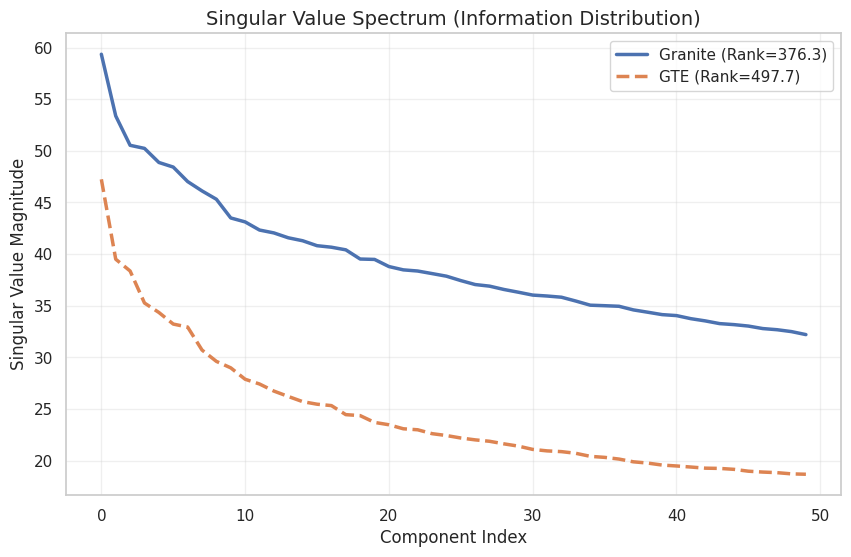

In [4]:
#!/usr/bin/env python3
"""
Model Strength Comparison: Spectral Capacity & Containment.
Metric: Determines if Granite is 'stronger' (richer information) than GTE.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from transformers import AutoTokenizer, AutoModel
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------
# Configuration
# -------------------------
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
SRC_NAME = "ibm-granite/granite-embedding-278m-multilingual" # Candidate
TGT_NAME = "thenlper/gte-base"                               # Reference
MAPPER_PATH = '/home/pallucchini/NEW_ALIGNMENT_METHOD/align_new/saved_mappers_official_gra_gte_1M_MacroStr_SimTlm/official_mapper_src2tgt.pt'

NUM_SAMPLES = 1000  # Sufficient for spectral analysis

# -------------------------
# Helpers
# -------------------------
class TransformerEmbeddingMapper(nn.Module):
    def __init__(self, emb_dim, hidden_dim=1024, n_layers=4, n_heads=16, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(emb_dim, hidden_dim)
        self.memory_proj = nn.Linear(emb_dim, hidden_dim) 
        decoder_layer = nn.TransformerDecoderLayer(d_model=hidden_dim, nhead=n_heads, dim_feedforward=hidden_dim*4, dropout=dropout, activation='gelu', batch_first=True)
        self.transformer = nn.TransformerDecoder(decoder_layer, num_layers=n_layers)
        self.output_proj = nn.Linear(hidden_dim, emb_dim)
        self.ln = nn.LayerNorm(emb_dim)

    def forward(self, x, memory):
        if x.dim() == 2: x = x.unsqueeze(1)
        h = self.input_proj(x)
        mem_proj = self.memory_proj(memory.unsqueeze(1) if memory.dim() == 2 else memory)
        h = self.transformer(tgt=h, memory=mem_proj) 
        out = self.output_proj(h)
        out = self.ln(out)
        return out[:, 0, :]

@torch.no_grad()
def get_embeddings(texts, tokenizer, model):
    model.eval()
    inputs = tokenizer(texts, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
    out = model(**inputs)
    mask = inputs['attention_mask'].unsqueeze(-1)
    emb = (out.last_hidden_state * mask).sum(1) / mask.sum(1).clamp(min=1)
    return emb

def compute_effective_rank(embeddings):
    """
    Computes the Effective Rank (Entropy of Singular Values).
    Higher = Richer Information / Less Collapse.
    """
    # 1. Center the data
    embeddings = embeddings - embeddings.mean(dim=0, keepdim=True)
    
    # 2. SVD
    _, S, _ = torch.svd(embeddings)
    
    # 3. Normalize Singular Values
    # We use Singular Values (S) to get eigenvalues of covariance (S^2)
    # Effective Rank is often defined on the normalized singular values directly or eigenvalues.
    # Standard definition: Roy & Vetterli (2007) uses normalized singular values p_k
    p = S / S.sum()
    
    # 4. Entropy
    entropy = -torch.sum(p * torch.log(p + 1e-9))
    
    # 5. Effective Rank
    erank = torch.exp(entropy).item()
    return erank, S.cpu().numpy()

# -------------------------
# Main Analysis
# -------------------------
def main():
    print(f"[*] Device: {DEVICE}")
    
    # 1. Load Data
    print(f"[*] Loading {NUM_SAMPLES} samples...")
    ds = load_dataset("jxm/nq_corpus_dpr", split="train", streaming=True)
    texts = []
    for x in ds.take(NUM_SAMPLES):
        t = x.get("text", "") or x.get("document_text", "")
        if t: texts.append(t[:200])

    # 2. Load Models
    print("[*] Loading Models...")
    s_tok = AutoTokenizer.from_pretrained(SRC_NAME); s_mod = AutoModel.from_pretrained(SRC_NAME).to(DEVICE)
    t_tok = AutoTokenizer.from_pretrained(TGT_NAME); t_mod = AutoModel.from_pretrained(TGT_NAME).to(DEVICE)

    mapper = TransformerEmbeddingMapper(768, hidden_dim=768).to(DEVICE)
    mapper.load_state_dict(torch.load(MAPPER_PATH, map_location=DEVICE))
    mapper.eval()

    # 3. Compute Embeddings
    print("[*] Computing Embeddings...")
    emb_granite = get_embeddings(texts, s_tok, s_mod) # Source
    emb_gte = get_embeddings(texts, t_tok, t_mod)     # Target
    
    # 4. Compute Effective Rank (Intrinsic Strength)
    print("[*] Calculating Spectral Capacity...")
    rank_granite, s_granite = compute_effective_rank(emb_granite)
    rank_gte, s_gte = compute_effective_rank(emb_gte)
    
    # 5. Compute Alignment Fidelity (Containment)
    # How well does Granite map to GTE?
    print("[*] Checking Containment (Alignment Fidelity)...")
    with torch.no_grad():
        mapped_granite = mapper(emb_granite, memory=emb_gte) # Align Granite to GTE space
    
    # Similarity: How close is Mapped_Granite to Real_GTE?
    # High Sim = Granite contains GTE info.
    sims = F.cosine_similarity(mapped_granite, emb_gte)
    fidelity = sims.mean().item()

    # -------------------------
    # REPORT
    # -------------------------
    print("\n" + "="*40)
    print("      MODEL STRENGTH ANALYSIS      ")
    print("="*40)
    print(f"1. Granite Effective Rank: {rank_granite:.2f}")
    print(f"2. GTE Effective Rank:     {rank_gte:.2f}")
    
    ratio = rank_granite / rank_gte
    print(f"-> Capacity Ratio (G/E):   {ratio:.2f}x")
    
    print(f"\n3. Alignment Fidelity:     {fidelity:.4f}")
    print("   (>0.90 implies Granite fully captures GTE semantics)")
    
    print("-" * 40)
    print("CONCLUSION:")
    
    if ratio > 1.05 and fidelity > 0.85:
        print("[WINNER: GRANITE]")
        print("Granite is STRONGER.")
        print("Reason: It has higher information capacity (Rank) AND successfully contains GTE's knowledge (High Fidelity).")
        print("It is the richer model.")
    elif ratio < 0.95:
        print("[WINNER: GTE]")
        print("GTE is STRONGER.")
        print("Reason: It encodes more information density than Granite.")
    else:
        print("[TIE]")
        print("The models have comparable capacity.")

    # -------------------------
    # PLOT SPECTRUM
    # -------------------------
    plt.figure(figsize=(10, 6))
    plt.plot(s_granite[:50], label=f'Granite (Rank={rank_granite:.1f})', linewidth=2.5)
    plt.plot(s_gte[:50], label=f'GTE (Rank={rank_gte:.1f})', linewidth=2.5, linestyle='--')
    plt.title("Singular Value Spectrum (Information Distribution)", fontsize=14)
    plt.ylabel("Singular Value Magnitude")
    plt.xlabel("Component Index")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.savefig("model_strength_spectrum.png", dpi=300)
    print(f"\n[+] Spectrum plot saved to model_strength_spectrum.png")

if __name__ == "__main__":
    main()